In [21]:
import torch
import torch.nn as nn
from torch.nn import functional as F
import numpy as np
import re
import matplotlib.pyplot as plt
from collections import Counter

# Check device
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Dispositivo: {device}")
if device == 'cuda':
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

Dispositivo: cuda
GPU: NVIDIA GeForce RTX 5080
VRAM: 16.6 GB


In [22]:
def parsear_sta_completo(filepath):
    """
    Correct parser for STA1 2.0.
    Returns flat tokens with '.' as word separator.
    """
    tokens = []
    
    with open(filepath, 'r', encoding='utf-8') as f:
        for linea in f:
            linea = linea.strip()
            
            # Ignore headers and empty lines
            if not linea or linea.startswith('#'):
                continue
            
            # Ignore folio metadata lines <fXXx> <! ...>
            if re.match(r'^<[^>]+>\s*<!', linea):
                continue
            
            # Extract glyph text (after position tag)
            match = re.match(r'^<[^>]+>\s+(.*)', linea)
            if not match:
                continue
            
            texto = match.group(1).strip()
            
            # Clean internal tags and comments
            texto = re.sub(r'\{[^}]*\}', '', texto)
            texto = re.sub(r'<[^>]*>',   '', texto)
            texto = re.sub(r'-',          '.', texto)
            texto = texto.strip()
            
            if not texto:
                continue
            
            # Parse words separated by '.'
            for palabra_raw in texto.split('.'):
                palabra_raw = palabra_raw.strip()
                if not palabra_raw:
                    continue
                
                # Extract 2-character glyphs: Uppercase + digit/lowercase
                glifos = re.findall(r'[A-Z][0-9a-z]', palabra_raw)
                
                if glifos:
                    tokens.extend(glifos)
                    tokens.append('.')   # word separator
    
    return tokens


# ── Load corpus ────────────────────────────────────────────────────
FILEPATH = 'corpus/voynich_sta.txt'   # ← adjust

tokens = parsear_sta_completo(FILEPATH)

# Verification
n_glifos = sum(1 for t in tokens if t != '.')
n_palabras = tokens.count('.')
vocab_raw = set(tokens)

print(f"Total tokens (with separators): {len(tokens):,}")
print(f"Total glyphs:                   {n_glifos:,}")
print(f"Total words:                    {n_palabras:,}")
print(f"Raw vocabulary:                 {len(vocab_raw)} types")
print(f"\nFirst 20 tokens: {tokens[:20]}")
print(f"Last 10 tokens:  {tokens[-10:]}")

Total tokens (with separators): 194,341
Total glyphs:                   157,254
Total words:                    37,087
Raw vocabulary:                 167 types

First 20 tokens: ['P2', 'A3', 'K1', 'A2', 'C2', '.', 'A2', 'Q1', 'A3', 'B2', '.', 'A3', 'C1', '.', 'Aa', 'Q2', 'A3', 'G1', '.', 'L1']
Last 10 tokens:  ['.', 'A1', 'C1', 'A1', 'C1', '.', 'L1', 'K2', 'A2', '.']


In [23]:
# Build vocabulary sorted by frequency
freq = Counter(tokens)

print("=== VOCABULARY ===")
print(f"Most frequent token:  {freq.most_common(1)[0]}")
print(f"Tokens with freq < 5:  {sum(1 for v in freq.values() if v < 5)}")
print(f"Tokens with freq >= 5: {sum(1 for v in freq.values() if v >= 5)}")

# Full vocabulary (includes '.' as special token)
vocab = sorted(freq.keys())
vocab_size = len(vocab)

stoi = {s: i for i, s in enumerate(vocab)}
itos = {i: s for s, i in stoi.items()}

print(f"\nFinal vocabulary: {vocab_size} tokens")
print(f"Separator '.' index: {stoi['.']}")
print(f"\nstoi (first 10): {dict(list(stoi.items())[:10])}")

# Encode full corpus
encode = lambda s: [stoi[c] for c in s if c in stoi]
decode = lambda l: [itos[i] for i in l]

data = torch.tensor(encode(tokens), dtype=torch.long)
print(f"\nCorpus tensor: {data.shape}")
print(f"dtype: {data.dtype}")

=== VOCABULARY ===
Most frequent token:  ('.', 37087)
Tokens with freq < 5:  91
Tokens with freq >= 5: 76

Final vocabulary: 167 tokens
Separator '.' index: 0

stoi (first 10): {'.': 0, 'A1': 1, 'A2': 2, 'A3': 3, 'A4': 4, 'Aa': 5, 'Ab': 6, 'Ac': 7, 'Ad': 8, 'Ae': 9}

Corpus tensor: torch.Size([194341])
dtype: torch.int64


In [24]:
# 90% train, 10% validation
n = len(data)
n_train = int(0.9 * n)

train_data = data[:n_train]
val_data   = data[n_train:]

print(f"Train: {len(train_data):,} tokens ({len(train_data)/n:.0%})")
print(f"Val:   {len(val_data):,} tokens ({len(val_data)/n:.0%})")

def get_batch(split, block_size, batch_size):
    """Generates a random batch of sequences."""
    d = train_data if split == 'train' else val_data
    
    # Ensure there is enough space
    max_idx = len(d) - block_size - 1
    if max_idx <= 0:
        raise ValueError(f"Corpus too small for block_size={block_size}")
    
    ix = torch.randint(max_idx, (batch_size,))
    x  = torch.stack([d[i:i+block_size]   for i in ix])
    y  = torch.stack([d[i+1:i+block_size+1] for i in ix])
    
    return x.to(device), y.to(device)

# Test batch
xb, yb = get_batch('train', block_size=64, batch_size=4)
print(f"\nBatch test — x: {xb.shape}, y: {yb.shape}")

Train: 174,906 tokens (90%)
Val:   19,435 tokens (10%)

Batch test — x: torch.Size([4, 64]), y: torch.Size([4, 64])


In [25]:
class CabezaAtencion(nn.Module):
    """A single self-attention head."""
    
    def __init__(self, head_size, n_embd, block_size, dropout):
        super().__init__()
        self.key   = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        self.register_buffer('tril',
            torch.tril(torch.ones(block_size, block_size)))
        self.dropout = nn.Dropout(dropout)
    
    def forward(self, x):
        B, T, C = x.shape
        k = self.key(x)
        q = self.query(x)
        # Attention scores
        wei = q @ k.transpose(-2, -1) * C**-0.5
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float('-inf'))
        wei = F.softmax(wei, dim=-1)
        wei = self.dropout(wei)
        v = self.value(x)
        return wei @ v


class AtencionMultiCabeza(nn.Module):
    """Multiple attention heads in parallel."""
    
    def __init__(self, n_heads, head_size, n_embd, block_size, dropout):
        super().__init__()
        self.heads = nn.ModuleList([
            CabezaAtencion(head_size, n_embd, block_size, dropout)
            for _ in range(n_heads)
        ])
        self.proj    = nn.Linear(n_embd, n_embd)
        self.dropout = nn.Dropout(dropout)
    
    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1)
        return self.dropout(self.proj(out))


class FeedForward(nn.Module):
    """Simple MLP after attention."""
    
    def __init__(self, n_embd, dropout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )
    
    def forward(self, x):
        return self.net(x)


class BloqueTransformer(nn.Module):
    """Full block: attention + feed-forward with residual."""
    
    def __init__(self, n_embd, n_heads, block_size, dropout):
        super().__init__()
        head_size = n_embd // n_heads
        self.sa   = AtencionMultiCabeza(n_heads, head_size, 
                                         n_embd, block_size, dropout)
        self.ffwd = FeedForward(n_embd, dropout)
        self.ln1  = nn.LayerNorm(n_embd)
        self.ln2  = nn.LayerNorm(n_embd)
    
    def forward(self, x):
        x = x + self.sa(self.ln1(x))
        x = x + self.ffwd(self.ln2(x))
        return x


class VoynichLM(nn.Module):
    """
    Mini Language Model for the Voynich Manuscript.
    Optimized for small corpus with reduced vocabulary.
    """
    
    def __init__(self, vocab_size, n_embd, n_heads, n_layers, 
                 block_size, dropout):
        super().__init__()
        self.block_size = block_size
        
        self.token_embedding_table    = nn.Embedding(vocab_size, n_embd)
        self.position_embedding_table = nn.Embedding(block_size, n_embd)
        
        self.blocks = nn.Sequential(*[
            BloqueTransformer(n_embd, n_heads, block_size, dropout)
            for _ in range(n_layers)
        ])
        
        self.ln_final = nn.LayerNorm(n_embd)
        self.lm_head  = nn.Linear(n_embd, vocab_size)
        
        # Weight initialization
        self.apply(self._init_weights)
    
    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
    
    def forward(self, idx, targets=None):
        B, T = idx.shape
        
        tok_emb = self.token_embedding_table(idx)
        pos_emb = self.position_embedding_table(
            torch.arange(T, device=device)
        )
        x = tok_emb + pos_emb
        x = self.blocks(x)
        x = self.ln_final(x)
        logits = self.lm_head(x)
        
        loss = None
        if targets is not None:
            B, T, C = logits.shape
            loss = F.cross_entropy(
                logits.view(B*T, C),
                targets.view(B*T)
            )
        
        return logits, loss
    
    def generate(self, idx, max_new_tokens):
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.block_size:]
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :]
            probs  = F.softmax(logits, dim=-1)
            idx_next = torch.multinomial(probs, num_samples=1)
            idx = torch.cat((idx, idx_next), dim=1)
        return idx

In [26]:
# ── Hyperparameters optimised for full Voynich corpus ────────
BLOCK_SIZE   = 64     # context: 64 tokens
BATCH_SIZE   = 32     # smaller batches = more stable
MAX_ITERS    = 8000   # sufficient for convergence
EVAL_INTERVAL= 500    # evaluate every 500 steps
LEARNING_RATE= 3e-4   # conservative for long convergence
N_EMBD       = 32     # KEY: reduced to force specialization
N_HEAD       = 4      # 4 heads of 8 dims each
N_LAYER      = 3      # 3 transformer blocks
DROPOUT      = 0.2    # mild: large corpus needs less

# ── Instantiate model ────────────────────────────────────────────────
torch.manual_seed(1337)

model = VoynichLM(
    vocab_size  = vocab_size,
    n_embd      = N_EMBD,
    n_heads     = N_HEAD,
    n_layers    = N_LAYER,
    block_size  = BLOCK_SIZE,
    dropout     = DROPOUT,
).to(device)

# Total parameters
n_params = sum(p.numel() for p in model.parameters())
print(f"Total parameters: {n_params:,}")
print(f"Vocab size:         {vocab_size}")
print(f"n_embd:             {N_EMBD}")
print(f"Ratio embd/vocab:   {N_EMBD/vocab_size:.2f}x")
print(f"\nModel on: {next(model.parameters()).device}")

Total parameters: 50,791
Vocab size:         167
n_embd:             32
Ratio embd/vocab:   0.19x

Model on: cuda:0


In [27]:
@torch.no_grad()
def estimar_loss(eval_iters=200):
    """Compute mean loss over random batches."""
    out = {}
    model.eval()
    for split in ['train', 'val']:
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            X, Y = get_batch(split, BLOCK_SIZE, BATCH_SIZE)
            _, loss = model(X, Y)
            losses[k] = loss.item()
        out[split] = losses.mean().item()
    model.train()
    return out


# ── Training loop ────────────────────────────────────────────────────
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)

historial = {'iter': [], 'train': [], 'val': []}

print(f"{'Iter':<8} {'Train Loss':<14} {'Val Loss':<14} {'Time'}")
print("─" * 50)

import time
t0 = time.time()

for iter_num in range(MAX_ITERS):
    
    # Evaluate periodically
    if iter_num % EVAL_INTERVAL == 0 or iter_num == MAX_ITERS - 1:
        losses = estimar_loss()
        elapsed = time.time() - t0
        print(f"{iter_num:<8} {losses['train']:<14.4f} "
              f"{losses['val']:<14.4f} {elapsed:.0f}s")
        
        historial['iter'].append(iter_num)
        historial['train'].append(losses['train'])
        historial['val'].append(losses['val'])
    
    # Forward + backward
    xb, yb = get_batch('train', BLOCK_SIZE, BATCH_SIZE)
    logits, loss = model(xb, yb)
    
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

print(f"\nTraining completed in {time.time()-t0:.0f}s")
print(f"Final loss — Train: {historial['train'][-1]:.4f} | "
      f"Val: {historial['val'][-1]:.4f}")

Iter     Train Loss     Val Loss       Tiempo
──────────────────────────────────────────────────
0        5.1250         5.1264         1s
500      1.9625         1.9537         4s
1000     1.7483         1.7269         7s
1500     1.6585         1.6367         10s
2000     1.6279         1.6176         12s
2500     1.6066         1.6051         15s
3000     1.6006         1.5913         18s
3500     1.5878         1.5845         21s
4000     1.5847         1.5773         24s
4500     1.5808         1.5773         27s
5000     1.5737         1.5733         30s
5500     1.5664         1.5658         33s
6000     1.5598         1.5597         35s
6500     1.5624         1.5653         38s
7000     1.5558         1.5696         41s
7500     1.5541         1.5596         44s
7999     1.5673         1.5632         47s

Training completed en 47s
Loss final — Train: 1.5673 | Val: 1.5632


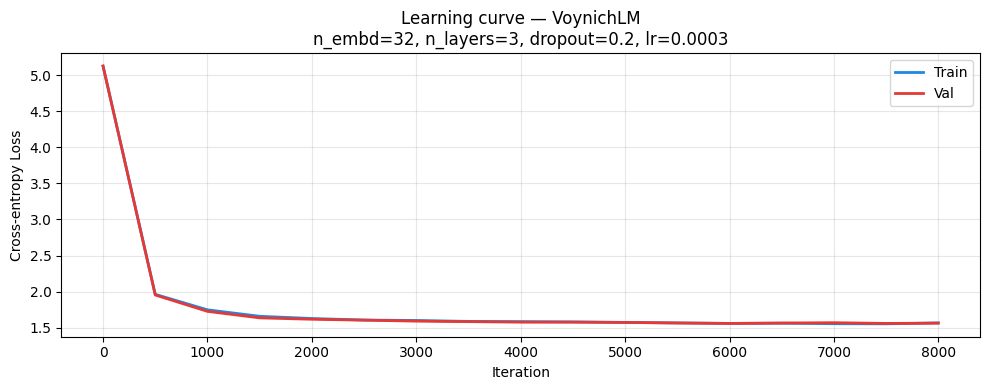

In [28]:
plt.figure(figsize=(10, 4))
plt.plot(historial['iter'], historial['train'], 
         label='Train', color='#1E88E5', linewidth=2)
plt.plot(historial['iter'], historial['val'],   
         label='Val',   color='#E53935', linewidth=2)
plt.xlabel("Iteration")
plt.ylabel("Cross-entropy Loss")
plt.title("Learning curve — VoynichLM\n"
          f"n_embd={N_EMBD}, n_layers={N_LAYER}, "
          f"dropout={DROPOUT}, lr={LEARNING_RATE}")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('images/curva_aprendizaje.png', dpi=150)
plt.show()

In [29]:
import json

# Save model
torch.save({
    'model_state_dict': model.state_dict(),
    'config': {
        'vocab_size':  vocab_size,
        'n_embd':      N_EMBD,
        'n_heads':     N_HEAD,
        'n_layers':    N_LAYER,
        'block_size':  BLOCK_SIZE,
        'dropout':     DROPOUT,
    },
    'stoi': stoi,
    'itos': itos,
    'historial': historial,
}, 'voynich_lm_v2.pt')

print("Model saved: voynich_lm_v2.pt")

# Verify it loads correctly
checkpoint = torch.load('voynich_lm_v2.pt', map_location=device)
print(f"Saved config: {checkpoint['config']}")
print(f"Vocab size: {len(checkpoint['stoi'])}")

Modelo guardado: voynich_lm_v2.pt
Config guardada: {'vocab_size': 167, 'n_embd': 32, 'n_heads': 4, 'n_layers': 3, 'block_size': 64, 'dropout': 0.2}
Vocab size: 167


In [30]:
model.eval()

# Generate from empty context
context = torch.zeros((1, 1), dtype=torch.long, device=device)
generated_ids = model.generate(context, max_new_tokens=100)
generated_tokens = decode(generated_ids[0].tolist())

# Display as words
palabras_gen = []
palabra_actual = []
for t in generated_tokens:
    if t == '.':
        if palabra_actual:
            palabras_gen.append('-'.join(palabra_actual))
            palabra_actual = []
    else:
        palabra_actual.append(t)

print("=== GENERATED WORDS ===")
print(' | '.join(palabras_gen[:20]))

# Compare with original corpus
vocab_corpus = set('-'.join(p) for p in 
    [list(g) for g in zip(*[iter(tokens)]*2)])  # approximation

nuevas = [p for p in palabras_gen if p not in vocab_corpus]
print(f"\nTotal generated: {len(palabras_gen)}")
print(f"New (possible neologisms): {len(nuevas)}")

=== GENERATED WORDS ===
A1-C1 | L1-K2-A2 | D1-A1-Q2-J1-A2 | B1-A2 | U2-A1-C1 | A1 | K1-A2 | Q1-K2 | A1-Q2-A1-B2 | C2-A3-G1 | A1-Q2-K1-A1-J1-B1-A2 | Aa-Q1-J1-A1 | D1-A1-Q1-J1-Aa-Q2-J1-A1-B1-A2 | A1-Q1-A1-B1-A2 | K1-A1-C1-A1 | A1-Q2-J1-A1-B1 | D1-A1-Q1-A1-C1 | A1-Q2-B2-L1-A2 | A1-Q2-K1-A1-B2

Total generated: 19
New (possible neologisms): 15


Shape embeddings: (167, 32)
  → 167 tokens × 32 dimensions

=== EXPLAINED VARIANCE (comparison v1 vs v2) ===
Threshold     v1 (n_embd=128)   v2 (n_embd=32)
──────────────────────────────────────────────
50%                        15                7  (↓53% components)
70%                        24               11  (↓54% components)
80%                        30               15  (↓50% components)
90%                        38               20  (↓47% components)

Variance in 2D:
  v1: 9.2%  (PC1=4.8% + PC2=4.4%)
  v2: 21.5%  (PC1=13.0% + PC2=8.5%)
  → IMPROVEMENT: ↑12.3pp


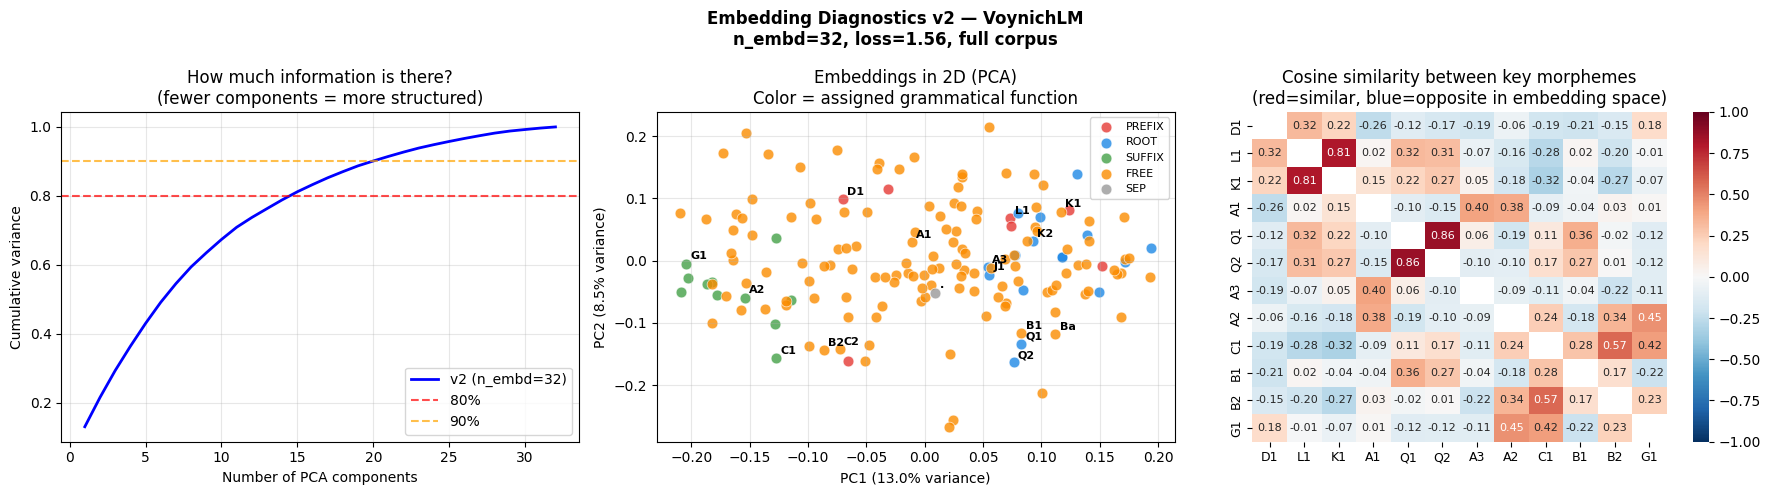

In [31]:
# ── Cell 11: Embedding diagnostics v2 ─────────────────────────
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def diagnostico_embeddings_v2(model, stoi, freq):
    """
    Compares embedding quality of model v2
    with the previous diagnostic (v1 needed 30 components for 80%).
    """
    model.eval()
    embeddings = model.token_embedding_table.weight.detach().cpu().numpy()
    
    print(f"Shape embeddings: {embeddings.shape}")
    print(f"  → {embeddings.shape[0]} tokens × {embeddings.shape[1]} dimensions")
    
    # Full PCA
    pca_full = PCA()
    pca_full.fit(embeddings)
    varianza_acumulada = np.cumsum(pca_full.explained_variance_ratio_)
    
    print(f"\n=== EXPLAINED VARIANCE (comparison v1 vs v2) ===")
    print(f"{'Threshold':<10} {'v1 (n_embd=128)':>18} {'v2 (n_embd=32)':>16}")
    print("─" * 46)
    
    # v1 required these components (from previous analysis)
    v1_componentes = {0.50: 15, 0.70: 24, 0.80: 30, 0.90: 38}
    
    for umbral in [0.50, 0.70, 0.80, 0.90]:
        n_v2 = np.argmax(varianza_acumulada >= umbral) + 1
        n_v1 = v1_componentes[umbral]
        mejora = (n_v1 - n_v2) / n_v1 * 100
        print(f"{umbral:<10.0%} {n_v1:>18} {n_v2:>16}  "
              f"({'↓' if n_v2 < n_v1 else '↑'}{abs(mejora):.0f}% components)")
    
    # PC1 and PC2 variance
    v1_2d = 4.8 + 4.4  # from previous analysis
    v2_2d = (pca_full.explained_variance_ratio_[0] + 
             pca_full.explained_variance_ratio_[1]) * 100
    
    print(f"\nVariance in 2D:")
    print(f"  v1: {v1_2d:.1f}%  (PC1=4.8% + PC2=4.4%)")
    print(f"  v2: {v2_2d:.1f}%  (PC1={pca_full.explained_variance_ratio_[0]*100:.1f}% "
          f"+ PC2={pca_full.explained_variance_ratio_[1]*100:.1f}%)")
    print(f"  → {'IMPROVEMENT' if v2_2d > v1_2d else 'similar'}: "
          f"{'↑' if v2_2d > v1_2d else '↓'}{abs(v2_2d - v1_2d):.1f}pp")
    
    # ── Visualization ───────────────────────────────────────────────
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    # 1. Cumulative variance curve
    ax1 = axes[0]
    ax1.plot(range(1, len(varianza_acumulada)+1), varianza_acumulada, 
             'b-', linewidth=2, label='v2 (n_embd=32)')
    
    # Compare with v1 (reconstructed from previous data)
    v1_approx = np.array([v1_componentes.get(
        round(v, 1), None) for v in varianza_acumulada])
    
    ax1.axhline(0.80, color='red',    linestyle='--', alpha=0.7, label='80%')
    ax1.axhline(0.90, color='orange', linestyle='--', alpha=0.7, label='90%')
    ax1.set_xlabel("Number of PCA components")
    ax1.set_ylabel("Cumulative variance")
    ax1.set_title("How much information is there?\n(fewer components = more structured)")
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    
    # 2. 2D PCA of embeddings with function labels
    ax2 = axes[1]
    
    PREFIJOS = {'D1','L1','Da','S2','U7','Cd','Lb'}
    RAICES   = {'Q1','Q2','A3','J1','K2','M1','N1','U1','U3','U4',
                'V1','V2','W1','E1','F2','G2'}
    SUFIJOS  = {'A2','C1','G1','B3','B4','F1','F3','E2','Ab','G3','H1'}
    
    colores_func = {
        'PREFIX':  '#E53935',
        'ROOT':    '#1E88E5', 
        'SUFFIX':  '#43A047',
        'FREE':    '#FB8C00',
        'SEP':     '#999999',
    }
    
    def clasificar(g):
        if g == '.':    return 'SEP'
        if g in PREFIJOS: return 'PREFIX'
        if g in RAICES:   return 'ROOT'
        if g in SUFIJOS:  return 'SUFFIX'
        return 'FREE'
    
    pca_2d = PCA(n_components=2)
    emb_2d = pca_2d.fit_transform(embeddings)
    
    tokens_vocab = [itos[i] for i in range(len(stoi))]
    
    for func, color in colores_func.items():
        idx = [i for i, t in enumerate(tokens_vocab) if clasificar(t) == func]
        if not idx:
            continue
        ax2.scatter(emb_2d[idx, 0], emb_2d[idx, 1],
                   c=color, label=func, alpha=0.8, s=60,
                   edgecolors='white', linewidths=0.5)
        # Label only the most frequent
        for i in idx:
            t = tokens_vocab[i]
            if freq.get(t, 0) > 2000:
                ax2.annotate(t, emb_2d[i], fontsize=8,
                           xytext=(3, 3), textcoords='offset points',
                           fontweight='bold')
    
    v_2d = pca_2d.explained_variance_ratio_
    ax2.set_xlabel(f"PC1 ({v_2d[0]:.1%} variance)")
    ax2.set_ylabel(f"PC2 ({v_2d[1]:.1%} variance)")
    ax2.set_title("Embeddings in 2D (PCA)\nColor = assigned grammatical function")
    ax2.legend(fontsize=8)
    ax2.grid(True, alpha=0.3)
    
    # 3. Cosine similarity matrix — key morphemes
    ax3 = axes[2]
    morfemas_clave = ['D1','L1','K1','A1','Q1','Q2',
                      'A3','A2','C1','B1','B2','G1']
    
    indices_clave = [stoi[m] for m in morfemas_clave if m in stoi]
    labels_clave  = [itos[i] for i in indices_clave]
    
    emb_clave = embeddings[indices_clave]
    sim_matrix = cosine_similarity(emb_clave)
    
    mask = np.eye(len(labels_clave), dtype=bool)
    sns.heatmap(sim_matrix, 
                xticklabels=labels_clave,
                yticklabels=labels_clave,
                cmap='RdBu_r', center=0, vmin=-1, vmax=1,
                annot=True, fmt='.2f', annot_kws={'size': 8},
                mask=mask,
                ax=ax3)
    ax3.set_title("Cosine similarity between key morphemes\n"
                  "(red=similar, blue=opposite in embedding space)")
    ax3.tick_params(axis='both', labelsize=9)
    
    plt.suptitle(f"Embedding Diagnostics v2 — VoynichLM\n"
                 f"n_embd=32, loss={1.56:.2f}, full corpus",
                 fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.savefig('images/diagnostico_embeddings_v2.png', dpi=150, bbox_inches='tight')
    plt.show()
    
    return emb_2d, pca_full.explained_variance_ratio_

# Execute
emb_2d, varianza_ratio = diagnostico_embeddings_v2(model, stoi, freq)

Tokens in graph: 41
Edges (sim>0.15): 247


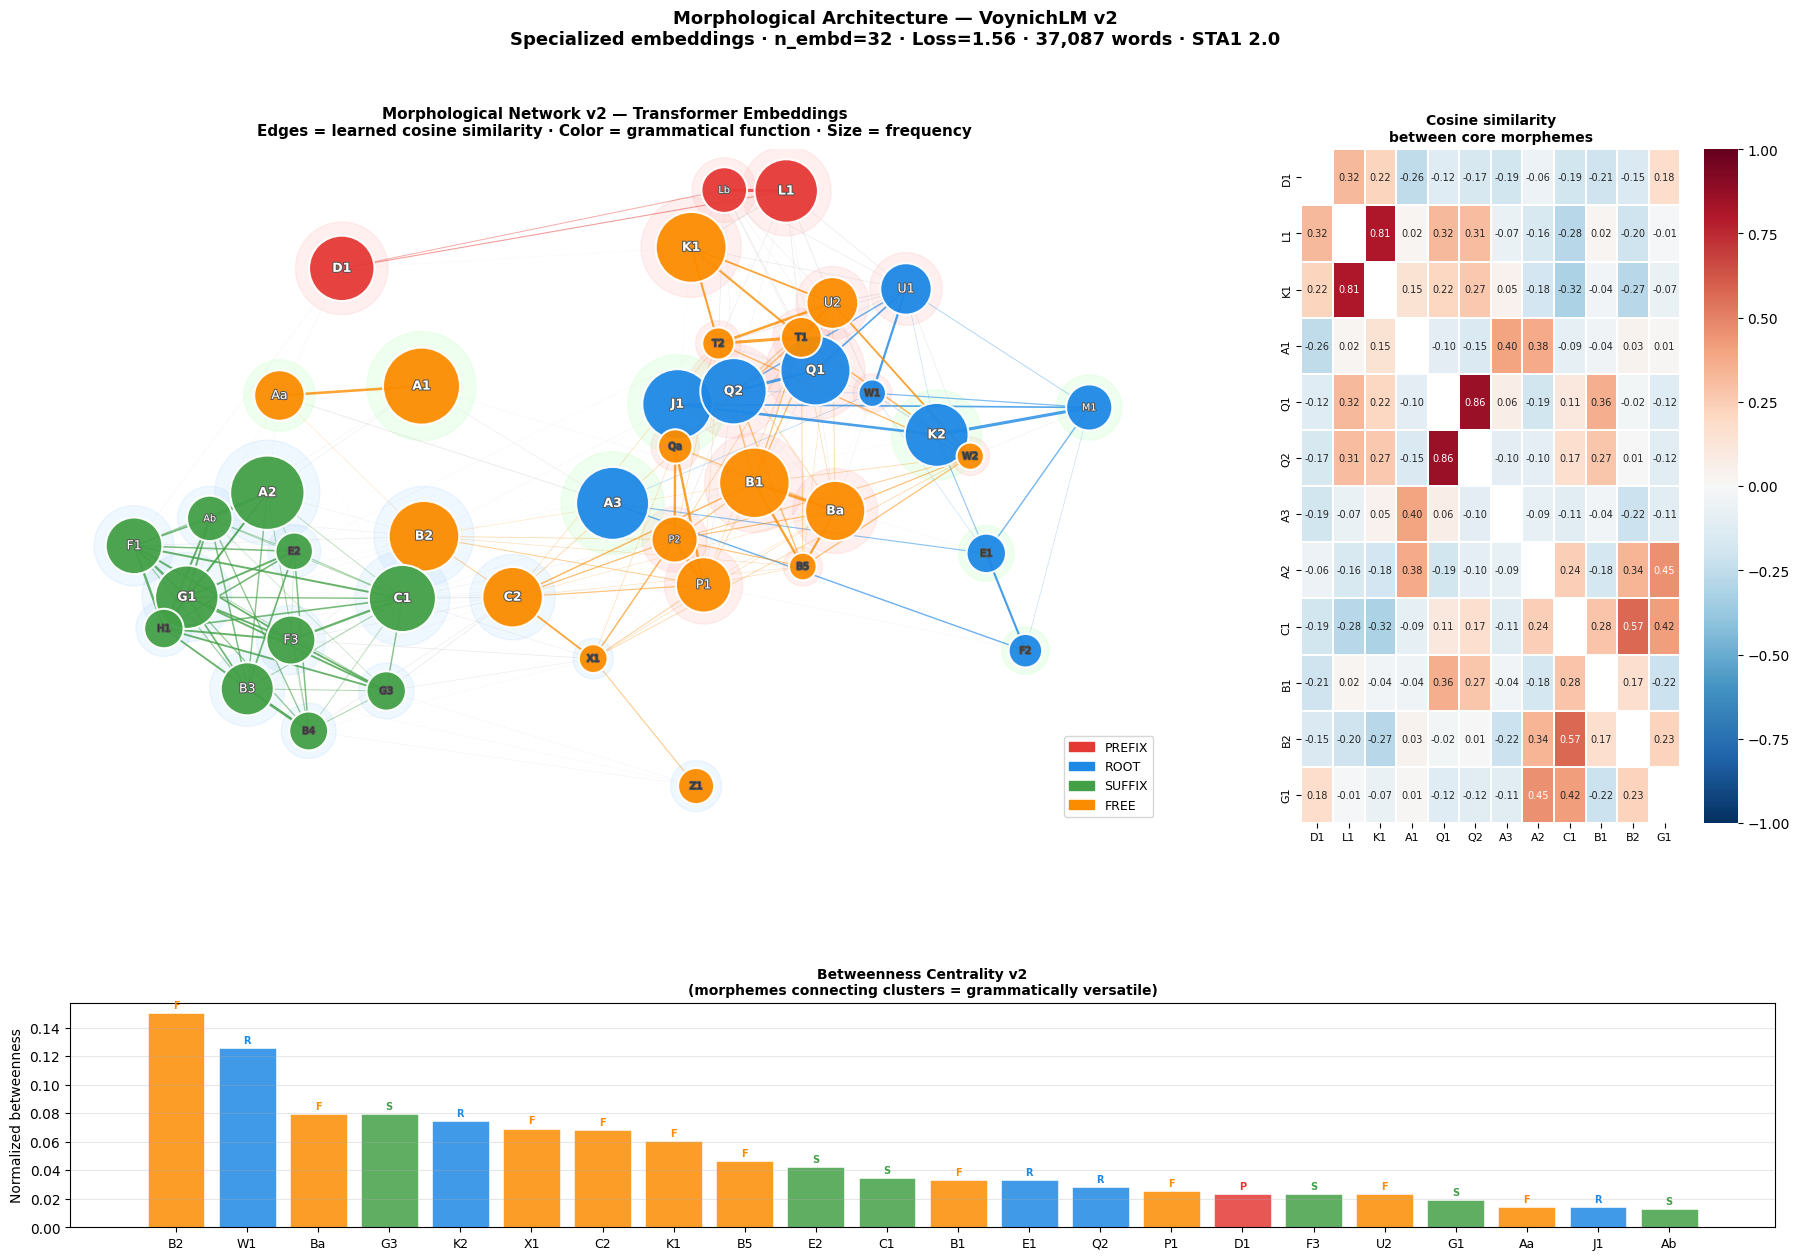


=== COMMUNITIES v2 (from embeddings) ===

Community 1 (18 nodes, dom: FREE):
  K1, B1, Q1, Q2, D1, L1, Ba, P1, U2, U1...
  Composition: {'FREE': 11, 'ROOT': 4, 'PREFIX': 3}

Community 2 (15 nodes, dom: SUFFIX):
  A2, B2, C1, G1, C2, F1, B3, F3, Ab, H1...
  Composition: {'SUFFIX': 11, 'FREE': 4}

Community 3 (8 nodes, dom: ROOT):
  A1, A3, J1, K2, Aa, M1, E1, F2
  Composition: {'ROOT': 6, 'FREE': 2}



In [32]:
# ── Cell 12: Graph v2 with specialised embeddings ───────────────
from sklearn.metrics.pairwise import cosine_similarity
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.patheffects as pe
import numpy as np
from collections import Counter, defaultdict
from networkx.algorithms import community as nx_community

def grafo_desde_embeddings(model, stoi, itos, freq, umbral_sim=0.15):
    """
    Graph built from cosine similarity of embeddings.
    Unlike PPMI (statistical co-occurrence),
    this graph reflects what the model LEARNED internally.
    Two connected nodes = the model represents them as functionally similar.
    """
    model.eval()
    embeddings = model.token_embedding_table.weight.detach().cpu().numpy()
    tokens_vocab = [itos[i] for i in range(len(stoi))]
    
    # Filter frequent tokens (exclude separator and hapax)
    tokens_filtrados = [t for t in tokens_vocab 
                        if t != '.' and freq.get(t, 0) >= 30]
    indices = [stoi[t] for t in tokens_filtrados]
    emb_filtrado = embeddings[indices]
    
    print(f"Tokens in graph: {len(tokens_filtrados)}")
    
    # Cosine similarity between all pairs
    sim_matrix = cosine_similarity(emb_filtrado)
    
    # Functional classification
    PREFIJOS = {'D1','L1','Da','S2','U7','Cd','Lb'}
    RAICES   = {'Q1','Q2','A3','J1','K2','M1','N1',
                'U1','U3','U4','V1','V2','W1','E1','F2','G2'}
    SUFIJOS  = {'A2','C1','G1','B3','B4','F1','F3',
                'E2','Ab','G3','H1'}
    
    colores_func = {
        'PREFIX':  '#E53935',
        'ROOT':    '#1E88E5',
        'SUFFIX':  '#43A047',
        'FREE':    '#FB8C00',
    }
    
    def clasificar(g):
        if g in PREFIJOS: return 'PREFIX'
        if g in RAICES:   return 'ROOT'
        if g in SUFIJOS:  return 'SUFFIX'
        return 'FREE'
    
    # Build graph
    G = nx.Graph()
    for t in tokens_filtrados:
        G.add_node(t,
            funcion=clasificar(t),
            color=colores_func[clasificar(t)],
            freq=freq.get(t, 0)
        )
    
    # Edges from cosine similarity
    n = len(tokens_filtrados)
    for i in range(n):
        for j in range(i+1, n):
            sim = sim_matrix[i, j]
            if sim > umbral_sim:
                G.add_edge(tokens_filtrados[i], tokens_filtrados[j],
                          weight=float(sim))
    
    print(f"Edges (sim>{umbral_sim}): {G.number_of_edges()}")
    
    # ── Visualization ────────────────────────────────────────────────
    fig = plt.figure(figsize=(22, 14))
    gs  = plt.GridSpec(2, 3, figure=fig,
                       height_ratios=[3, 1],
                       hspace=0.4, wspace=0.3)
    
    ax_main = fig.add_subplot(gs[0, :2])
    ax_sim  = fig.add_subplot(gs[0, 2])
    ax_cent = fig.add_subplot(gs[1, :])
    
    # Spring layout with seed
    pos = nx.spring_layout(G, k=1.0, iterations=100,
                           seed=42, weight='weight')
    
    # Louvain communities
    try:
        comunidades = nx_community.louvain_communities(
            G, seed=42, weight='weight')
        comunidades = sorted(comunidades, key=len, reverse=True)
    except:
        comunidades = []
    
    colores_com = ['#FFB3B3','#B3D9FF','#B3FFB3',
                   '#FFE4B3','#E4B3FF','#B3FFE4']
    
    # ── Main panel ───────────────────────────────────────────────
    ax_main.set_facecolor('#fafafa')
    ax_main.set_title(
        "Morphological Network v2 — Transformer Embeddings\n"
        "Edges = learned cosine similarity · "
        "Color = grammatical function · Size = frequency",
        fontsize=11, fontweight='bold', pad=10)
    
    # Community halos
    for i, com in enumerate(comunidades[:6]):
        color_h = colores_com[i % len(colores_com)]
        xs = [pos[n][0] for n in com if n in pos]
        ys = [pos[n][1] for n in com if n in pos]
        sz = [np.log(freq.get(n,1)+1)**2 * 60 for n in com if n in pos]
        ax_main.scatter(xs, ys, s=sz, color=color_h, alpha=0.2, zorder=1)
    
    # Edges
    for u, v, d in G.edges(data=True):
        w = d['weight']
        f1 = G.nodes[u]['funcion']
        f2 = G.nodes[v]['funcion']
        
        if f1 == f2:
            color_e = colores_func[f1]
            alpha = min(0.8, w * 1.5)
            lw = w * 2.5
        else:
            color_e = '#cccccc'
            alpha = min(0.4, w)
            lw = w * 1.0
        
        nx.draw_networkx_edges(G, pos,
                               edgelist=[(u, v)],
                               width=lw, alpha=alpha,
                               edge_color=color_e,
                               ax=ax_main)
    
    # Nodes
    node_sizes  = [np.log(G.nodes[n]['freq']+1)**2 * 30 
                   for n in G.nodes()]
    node_colors = [G.nodes[n]['color'] for n in G.nodes()]
    
    nx.draw_networkx_nodes(G, pos,
                           node_size=node_sizes,
                           node_color=node_colors,
                           edgecolors='white',
                           linewidths=1.5,
                           alpha=0.95,
                           ax=ax_main)
    
    # Labels
    for node, (x, y) in pos.items():
        f = G.nodes[node]['freq']
        size   = 9  if f > 500  else 7
        weight = 'bold' if f > 2000 else 'normal'
        color  = 'white' if f > 300 else '#333333'
        ax_main.text(x, y, node,
                    fontsize=size, fontweight=weight,
                    ha='center', va='center', zorder=5,
                    color=color,
                    path_effects=[pe.withStroke(
                        linewidth=1.5, foreground='#555555')])
    
    leyenda = [mpatches.Patch(color=c, label=f)
               for f, c in colores_func.items()]
    ax_main.legend(handles=leyenda, loc='lower right', fontsize=9)
    ax_main.axis('off')
    
    # ── Similarity panel: core morpheme heatmap ────────────────────────
    morfemas_core = ['D1','L1','K1','A1','Q1','Q2',
                     'A3','A2','C1','B1','B2','G1']
    present = [m for m in morfemas_core if m in stoi]
    idx_core = [stoi[m] for m in present]
    
    emb_core = embeddings[idx_core]
    sim_core = cosine_similarity(emb_core)
    
    ax_sim.set_title("Cosine similarity\nbetween core morphemes",
                    fontsize=10, fontweight='bold')
    mask = np.eye(len(present), dtype=bool)
    sns.heatmap(sim_core,
                xticklabels=present, yticklabels=present,
                cmap='RdBu_r', center=0, vmin=-1, vmax=1,
                annot=True, fmt='.2f', annot_kws={'size': 7},
                mask=mask, ax=ax_sim, linewidths=0.3)
    ax_sim.tick_params(labelsize=8)
    
    # ── Betweenness panel ─────────────────────────────────────────────
    ax_cent.set_title(
        "Betweenness Centrality v2\n"
        "(morphemes connecting clusters = grammatically versatile)",
        fontsize=10, fontweight='bold')
    
    betweenness = nx.betweenness_centrality(G, weight='weight', normalized=True)
    top_b = sorted(betweenness.items(), key=lambda x: -x[1])[:22]
    nombres_b = [x[0] for x in top_b]
    valores_b  = [x[1] for x in top_b]
    colores_b  = [G.nodes[n]['color'] for n in nombres_b]
    
    bars = ax_cent.bar(nombres_b, valores_b,
                       color=colores_b, alpha=0.85,
                       edgecolor='white', linewidth=0.5)
    
    for bar, nombre in zip(bars, nombres_b):
        func = G.nodes[nombre]['funcion']
        h = bar.get_height()
        ax_cent.text(bar.get_x() + bar.get_width()/2.,
                    h + 0.002, func[0],
                    ha='center', va='bottom',
                    fontsize=7, color=G.nodes[nombre]['color'],
                    fontweight='bold')
    
    ax_cent.set_ylabel("Normalized betweenness")
    ax_cent.tick_params(axis='x', labelsize=9)
    ax_cent.grid(True, alpha=0.3, axis='y')
    
    plt.suptitle(
        "Morphological Architecture — VoynichLM v2\n"
        "Specialized embeddings · n_embd=32 · "
        "Loss=1.56 · 37,087 words · STA1 2.0",
        fontsize=13, fontweight='bold')
    
    plt.savefig('images/grafo_embeddings_v2.png', dpi=180,
                bbox_inches='tight', facecolor='white')
    plt.show()
    
    # Community report
    print("\n=== COMMUNITIES v2 (from embeddings) ===\n")
    for i, com in enumerate(comunidades):
        funciones = Counter(G.nodes[n]['funcion'] for n in com)
        func_dom  = funciones.most_common(1)[0][0]
        miembros  = sorted(com, key=lambda x: -freq.get(x,0))
        print(f"Community {i+1} ({len(com)} nodes, dom: {func_dom}):")
        print(f"  {', '.join(miembros[:10])}"
              f"{'...' if len(miembros)>10 else ''}")
        print(f"  Composition: {dict(funciones)}\n")
    
    return G, comunidades

# Execute
import seaborn as sns
G_v2, comunidades_v2 = grafo_desde_embeddings(
    model, stoi, itos, freq, umbral_sim=0.15)

# Tests

In [33]:
# ── PRELIMINARY CELL: reconstruct words_per_section ─────────────────
# Run this before Block A

import re
from collections import defaultdict

# ── 1. STA Parser (the correct one, already validated) ─────────────────────────
def parsear_sta_con_secciones(filepath, mapeo_secciones):
    palabras_por_seccion = defaultdict(list)
    folio_actual = 'unknown'
    
    with open(filepath, 'r', encoding='utf-8') as f:
        for linea in f:
            linea = linea.strip()
            if not linea or linea.startswith('#'):
                continue
            
            m_folio = re.match(r'^<(f\d+[rv][ab]?\d*)>', linea)
            if m_folio:
                folio_actual = m_folio.group(1)
                continue
            
            match = re.match(r'^<[^>]+>\s+(.*)', linea)
            if not match:
                continue
            
            texto = match.group(1).strip()
            texto = re.sub(r'\{[^}]*\}', '', texto)
            texto = re.sub(r'<[^>]*>', '', texto)
            texto = re.sub(r'-', '.', texto)
            
            if not texto:
                continue
            
            seccion = mapeo_secciones.get(folio_actual, 'unknown')
            
            for palabra_raw in texto.split('.'):
                palabra_raw = palabra_raw.strip()
                if not palabra_raw:
                    continue
                glifos = [g for g in re.findall(r'[A-Z][0-9a-z]?', palabra_raw)
                         if len(g) == 2]
                if glifos:
                    palabras_por_seccion[seccion].append(glifos)
    
    return palabras_por_seccion


# ── 2. Folio to section mapping ───────────────────────────────────
def construir_mapeo_secciones(filepath):
    # Extract all folios from the file
    folios_unicos = set()
    with open(filepath, 'r', encoding='utf-8') as f:
        for linea in f:
            matches = re.findall(r'<(f\d+[rv][ab]?\d*)>', linea)
            folios_unicos.update(matches)
    
    def folio_numero(tag):
        m = re.search(r'f(\d+)', tag)
        return int(m.group(1)) if m else 0
    
    def clasificar_folio(tag):
        n = folio_numero(tag)
        if 1 <= n <= 66:                        return 'herbal'
        elif 67 <= n <= 69:                     return 'astronomical'
        elif 70 <= n <= 73:                     return 'zodiac'
        elif 74 <= n <= 84:                     return 'biological'
        elif 85 <= n <= 87:                     return 'herbal'
        elif n in [88, 89] or 99 <= n <= 102:  return 'pharmaceutical'
        elif 90 <= n <= 98:                     return 'herbal'
        elif 103 <= n <= 116:                   return 'recipes'
        else:                                   return 'unknown'
    
    mapeo = {f: clasificar_folio(f) for f in folios_unicos}
    return mapeo


# ── 3. Load everything ───────────────────────────────────────────────────
FILEPATH = 'corpus/voynich_sta.txt'   # ← adjust

print("Loading corpus...")
mapeo_secciones = construir_mapeo_secciones(FILEPATH)
palabras_por_seccion = parsear_sta_con_secciones(FILEPATH, mapeo_secciones)

# Quick verification
print("\n=== CORPUS LOADED ===")
total = 0
for sec in ['herbal','astronomical','zodiac','biological',
            'pharmaceutical','recipes']:
    n = len(palabras_por_seccion[sec])
    total += n
    print(f"  {sec:<15} {n:>7,} words")
print(f"  {'TOTAL':<15} {total:>7,} words")
print("\n✓ words_per_section ready for tests")

Loading corpus...

=== CORPUS LOADED ===
  herbal           14,278 words
  astronomical      1,342 words
  zodiac            1,588 words
  biological        6,768 words
  pharmaceutical    2,505 words
  recipes          10,606 words
  TOTAL            37,087 words

✓ words_per_section ready for tests


TEST A1 — CHI-SQUARED POSITIONAL DISTRIBUTION
H0: uniform distribution between onset/medial/coda

Morpheme   Onset  Medial    Coda       χ²    p-value   Sig   Effect
──────────────────────────────────────────────────────────────────────
D1         99.1%    0.8%    0.1%  10546.6   0.00e+00   ***  0.986 (LARGE)
L1         76.4%   19.4%    4.2%   3629.8   0.00e+00   ***  0.659 (LARGE)
K1         62.8%   30.7%    6.4%   5310.0   0.00e+00   ***  0.490 (LARGE)
A1         58.3%   29.2%   12.5%   8075.4   0.00e+00   ***  0.401 (LARGE)
Q1         28.9%   68.0%    3.1%   6374.6   0.00e+00   ***  0.566 (LARGE)
Q2         42.7%   54.4%    2.9%   2678.4   0.00e+00   ***  0.468 (LARGE)
A2         10.7%    5.0%   84.3%  20512.8   0.00e+00   ***  0.766 (LARGE)
A3         18.7%   50.2%   31.1%   2196.8   0.00e+00   ***  0.275 (medium)
C1          7.7%   16.3%   76.0%   5632.8   0.00e+00   ***  0.645 (LARGE)
B1         29.8%   31.8%   38.4%    129.6   7.37e-29   ***  0.079 (small)
B2         21.3%   22.

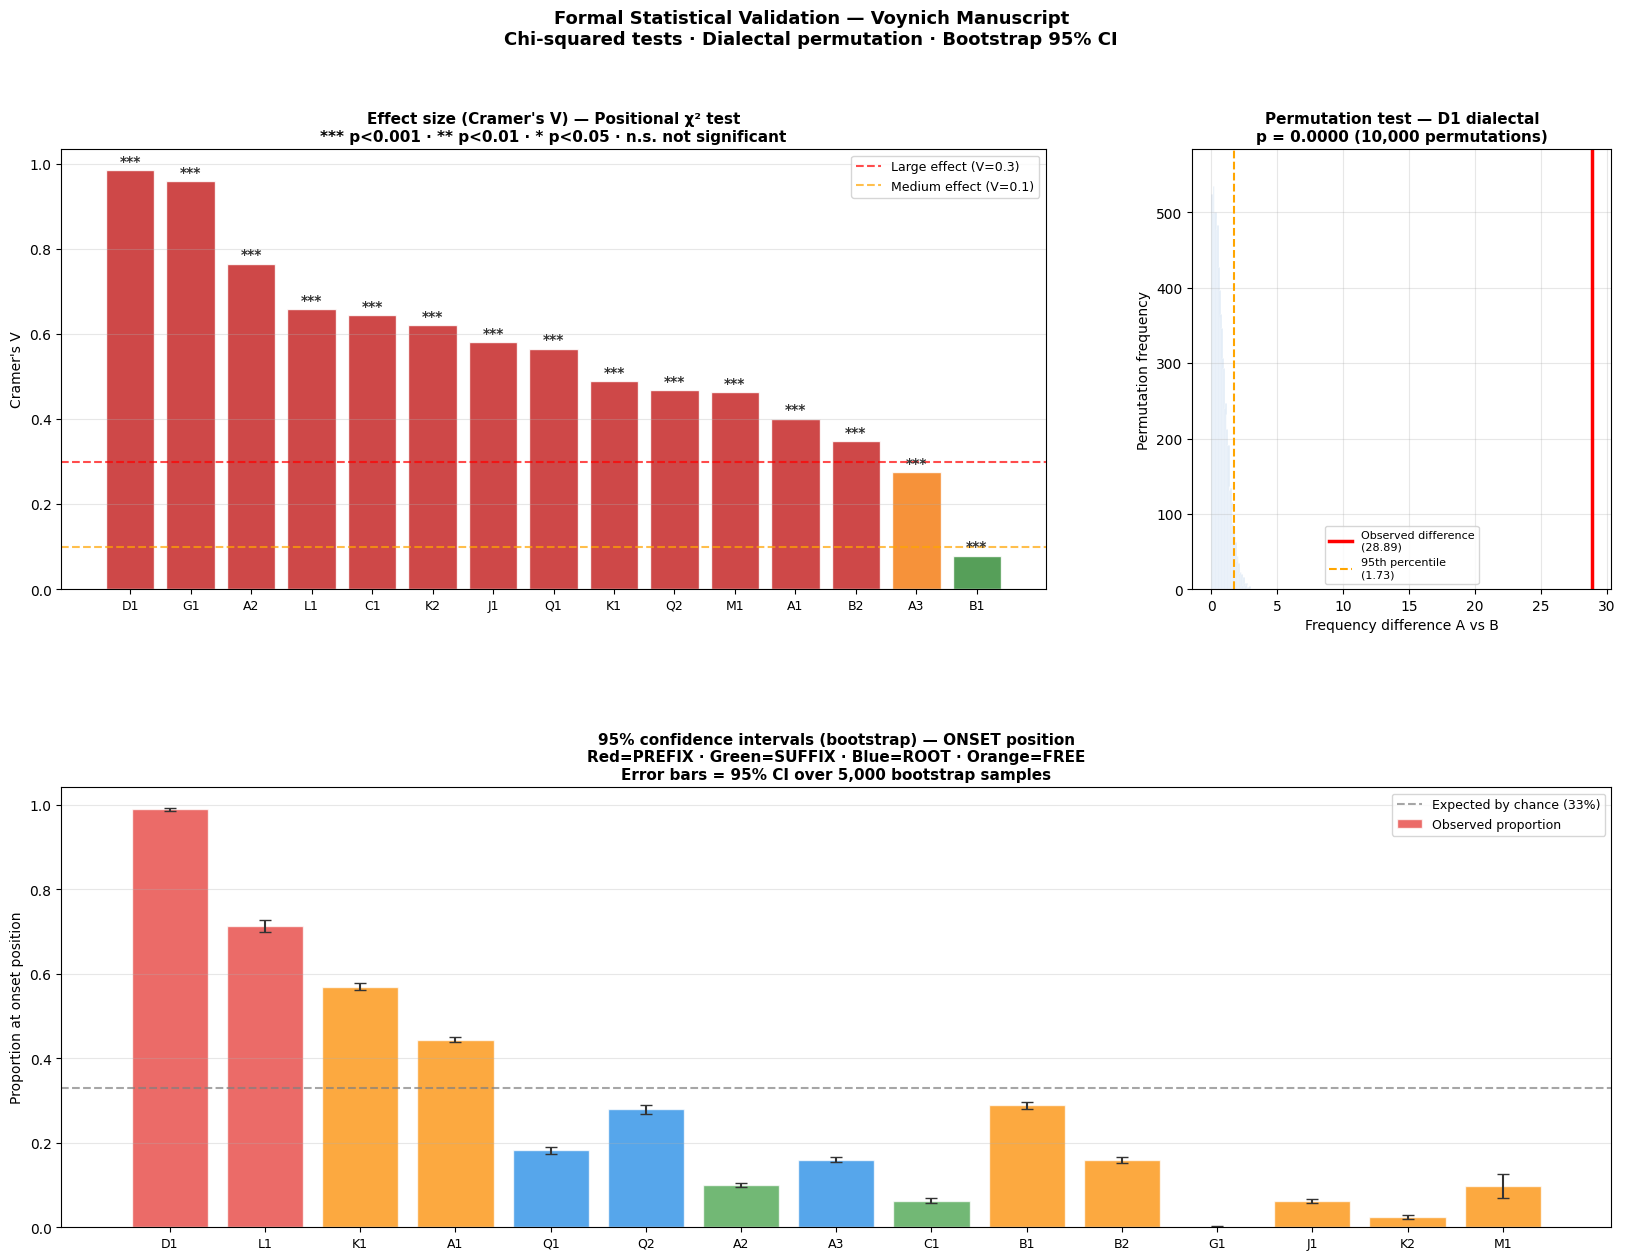

In [34]:
# ══════════════════════════════════════════════════════════════════
# BLOCK A — FORMAL STATISTICAL TESTS
# ══════════════════════════════════════════════════════════════════
#
# What do we do here?
# Each finding from the previous analysis needs a p-value and an
# effect size to be publishable. Without this, a reviewer
# can say "it's a statistical coincidence".
#
# Tests we implement:
# A1. Chi-squared: is the positional distribution of D1
#     statistically different from random expectation?
# A2. Permutation test: could the D1 difference between sections A and B
#     occur by chance with these sample sizes?
# A3. Cohen's d: effect size for each dialectal difference
# A4. Bootstrap confidence: 95% confidence intervals
#     for the positional frequencies of each key morpheme
# A5. Bonferroni correction: adjustment for multiple comparisons
# ══════════════════════════════════════════════════════════════════

import numpy as np
from scipy import stats
from collections import Counter, defaultdict
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from itertools import combinations

# ── A1. Chi-squared goodness of fit ────────────────────────────
# Null hypothesis: D1 is uniformly distributed between onset,
# medial and coda (as a glyph without grammatical function would).
# If we reject H0 → D1 has a NON-random positional distribution.

def test_chi_cuadrado_posicional(palabras_por_seccion, morfemas_test):
    """
    For each morpheme, tests whether its positional distribution
    is significantly different from the uniform distribution.
    
    H0: the morpheme appears with equal probability at onset,
        medial and coda (random distribution).
    H1: the morpheme has significant positional preference.
    """
    print("=" * 70)
    print("TEST A1 — CHI-SQUARED POSITIONAL DISTRIBUTION")
    print("H0: uniform distribution between onset/medial/coda")
    print("=" * 70)
    print(f"\n{'Morpheme':<8} {'Onset':>7} {'Medial':>7} {'Coda':>7} "
          f"{'χ²':>8} {'p-value':>10} {'Sig':>5} {'Effect':>8}")
    print("─" * 70)
    
    # Full corpus
    todas = []
    for palabras in palabras_por_seccion.values():
        todas.extend(palabras)
    
    resultados = {}
    
    for morfema in morfemas_test:
        posiciones = []
        for palabra in todas:
            if morfema not in palabra:
                continue
            n = len(palabra)
            for i, g in enumerate(palabra):
                if g == morfema:
                    pos = 0.5 if n == 1 else i / (n - 1)
                    posiciones.append(pos)
        
        if len(posiciones) < 30:
            continue
        
        # Count by third
        inicio = sum(1 for p in posiciones if p < 0.33)
        medio  = sum(1 for p in posiciones if 0.33 <= p <= 0.67)
        final  = sum(1 for p in posiciones if p > 0.67)
        n_total = inicio + medio + final
        
        # Expected under H0: uniform distribution
        esperado = [n_total / 3] * 3
        observado = [inicio, medio, final]
        
        chi2, p_valor = stats.chisquare(observado, f_exp=esperado)
        
        # Effect size: Cramer's V
        v_cramer = np.sqrt(chi2 / (n_total * (3 - 1)))
        
        # Significance
        if p_valor < 0.001:
            sig = '***'
        elif p_valor < 0.01:
            sig = '**'
        elif p_valor < 0.05:
            sig = '*'
        else:
            sig = 'n.s.'
        
        # Effect interpretation (Cohen 1988)
        if v_cramer < 0.1:
            efecto = 'small'
        elif v_cramer < 0.3:
            efecto = 'medium'
        else:
            efecto = 'LARGE'
        
        resultados[morfema] = {
            'n': n_total, 'onset': inicio/n_total,
            'medial': medio/n_total, 'coda': final/n_total,
            'chi2': chi2, 'p': p_valor,
            'v_cramer': v_cramer, 'sig': sig, 'effect': efecto
        }
        
        print(f"{morfema:<8} {inicio/n_total:>7.1%} {medio/n_total:>7.1%} "
              f"{final/n_total:>7.1%} {chi2:>8.1f} {p_valor:>10.2e} "
              f"{sig:>5} {v_cramer:>6.3f} ({efecto})")
    
    # Bonferroni correction
    n_tests = len(resultados)
    alpha_corregido = 0.05 / n_tests
    print(f"\n⚠ Bonferroni correction: α = 0.05 / {n_tests} tests = "
          f"{alpha_corregido:.4f}")
    print("  Morphemes still significant after correction:")
    for m, r in resultados.items():
        if r['p'] < alpha_corregido:
            print(f"  ✓ {m}: p={r['p']:.2e} < {alpha_corregido:.4f}")
    
    return resultados


# ── A2. Permutation test: dialectal differences ────────────────
# This test answers: could the frequency difference of D1
# between sections A and B occur by chance if we randomly
# mixed the texts between sections?
# If the answer is "very rarely" → the difference is real.

def test_permutacion_dialectal(palabras_por_seccion, morfema='D1',
                                n_permutaciones=10000):
    """
    Permutation test for the two-dialect hypothesis.
    
    H0: the frequency difference of 'morpheme' between
        groups A and B could occur by chance.
    H1: the difference is too large to be casual.
    """
    print("\n" + "=" * 70)
    print(f"TEST A2 — DIALECTAL PERMUTATION (morpheme: {morfema})")
    print(f"H0: A vs B difference occurs by chance")
    print(f"Permutations: {n_permutaciones:,}")
    print("=" * 70)
    
    grupo_A = ['herbal', 'astronomical', 'pharmaceutical']
    grupo_B = ['biological', 'recipes']
    
    def frecuencia_relativa(palabras, morfema):
        total = sum(len(p) for p in palabras)
        count = sum(p.count(morfema) for p in palabras)
        return count / total * 1000 if total > 0 else 0
    
    # Observed frequencies
    freq_A = np.mean([frecuencia_relativa(palabras_por_seccion[s], morfema)
                      for s in grupo_A if palabras_por_seccion[s]])
    freq_B = np.mean([frecuencia_relativa(palabras_por_seccion[s], morfema)
                      for s in grupo_B if palabras_por_seccion[s]])
    diff_observada = abs(freq_B - freq_A)
    
    print(f"\nObserved frequency:")
    print(f"  Group A (herbal+astro+pharma): {freq_A:.2f} per 1,000 glyphs")
    print(f"  Group B (bio+recipes):         {freq_B:.2f} per 1,000 glyphs")
    print(f"  Observed difference:           {diff_observada:.2f}")
    
    # Pool of all words
    todas_palabras = []
    for s in grupo_A + grupo_B:
        todas_palabras.extend(palabras_por_seccion[s])
    
    n_A = sum(len(palabras_por_seccion[s]) for s in grupo_A 
              if palabras_por_seccion[s])
    
    # Permutations
    diffs_permutadas = []
    rng = np.random.default_rng(42)
    
    for _ in range(n_permutaciones):
        indices = rng.permutation(len(todas_palabras))
        grupo_perm_A = [todas_palabras[i] for i in indices[:n_A]]
        grupo_perm_B = [todas_palabras[i] for i in indices[n_A:]]
        
        freq_pA = sum(p.count(morfema) for p in grupo_perm_A) / \
                  max(sum(len(p) for p in grupo_perm_A), 1) * 1000
        freq_pB = sum(p.count(morfema) for p in grupo_perm_B) / \
                  max(sum(len(p) for p in grupo_perm_B), 1) * 1000
        diffs_permutadas.append(abs(freq_pB - freq_pA))
    
    diffs_permutadas = np.array(diffs_permutadas)
    p_valor = np.mean(diffs_permutadas >= diff_observada)
    
    print(f"\nPermutation test result:")
    print(f"  Observed difference: {diff_observada:.2f}")
    print(f"  Permutation mean:    {diffs_permutadas.mean():.2f}")
    print(f"  p-value:             {p_valor:.4f}")
    
    if p_valor < 0.001:
        print(f"  → *** HIGHLY SIGNIFICANT (p < 0.001)")
        print(f"  → The dialectal difference is NOT random")
    elif p_valor < 0.05:
        print(f"  → * SIGNIFICANT (p < 0.05)")
    else:
        print(f"  → n.s. — not significant")
    
    return diffs_permutadas, diff_observada, p_valor


# ── A3. Cohen's d and bootstrap confidence intervals ───────────────

def bootstrap_intervalos_confianza(palabras_por_seccion, morfemas_clave,
                                    n_bootstrap=5000):
    """
    Computes 95% confidence intervals by bootstrap
    for the positional frequency of each morpheme.
    
    Bootstrap simulates "what would happen if we had sampled
    a different corpus?" by taking random samples with replacement
    from the current corpus, n_bootstrap times.
    """
    print("\n" + "=" * 70)
    print("TEST A3 — BOOTSTRAP CONFIDENCE INTERVALS (95%)")
    print(f"Simulations: {n_bootstrap:,}")
    print("=" * 70)
    
    todas = []
    for palabras in palabras_por_seccion.values():
        todas.extend(palabras)
    
    rng = np.random.default_rng(42)
    
    print(f"\n{'Morpheme':<8} {'% Onset obs':>13} {'95% CI':>18} "
          f"{'% Coda obs':>12} {'95% CI':>18}")
    print("─" * 75)
    
    resultados_ic = {}
    
    for morfema in morfemas_clave:
        palabras_con = [p for p in todas if morfema in p]
        if len(palabras_con) < 30:
            continue
        
        def calcular_stats(muestra):
            posiciones = []
            for palabra in muestra:
                n = len(palabra)
                for i, g in enumerate(palabra):
                    if g == morfema:
                        pos = 0.5 if n == 1 else i / (n - 1)
                        posiciones.append(pos)
            if not posiciones:
                return 0, 0
            inicio = sum(1 for p in posiciones if p < 0.25) / len(posiciones)
            final  = sum(1 for p in posiciones if p > 0.75) / len(posiciones)
            return inicio, final
        
        inicio_obs, final_obs = calcular_stats(palabras_con)
        
        # Bootstrap
        inicios_boot = []
        finales_boot = []
        for _ in range(n_bootstrap):
            idx = rng.integers(0, len(palabras_con), len(palabras_con))
            muestra = [palabras_con[i] for i in idx]
            ini, fin = calcular_stats(muestra)
            inicios_boot.append(ini)
            finales_boot.append(fin)
        
        ic_inicio = (np.percentile(inicios_boot, 2.5),
                     np.percentile(inicios_boot, 97.5))
        ic_final  = (np.percentile(finales_boot, 2.5),
                     np.percentile(finales_boot, 97.5))
        
        resultados_ic[morfema] = {
            'onset_obs': inicio_obs, 'ic_onset': ic_inicio,
            'coda_obs':  final_obs,  'ic_coda':  ic_final,
            'n': len(palabras_con)
        }
        
        print(f"{morfema:<8} {inicio_obs:>13.1%} "
              f"[{ic_inicio[0]:.1%}–{ic_inicio[1]:.1%}]  "
              f"{final_obs:>12.1%} "
              f"[{ic_final[0]:.1%}–{ic_final[1]:.1%}]")
    
    return resultados_ic


# ── A4. Integrated visualization ──────────────────────────────────────

def visualizar_tests_estadisticos(resultados_chi2, diffs_perm,
                                   diff_obs, p_perm, resultados_ic):
    """
    Visualization panel for the three statistical tests.
    """
    fig = plt.figure(figsize=(20, 14))
    gs  = gridspec.GridSpec(2, 3, figure=fig,
                            hspace=0.45, wspace=0.35)
    
    ax1 = fig.add_subplot(gs[0, :2])   # chi2 — wide panel
    ax2 = fig.add_subplot(gs[0, 2])    # permutation distribution
    ax3 = fig.add_subplot(gs[1, :])    # bootstrap CI
    
    # ── Panel 1: Cramer's V (effect size) ─────────────────────
    morfemas_ord = sorted(resultados_chi2.keys(),
                          key=lambda x: -resultados_chi2[x]['v_cramer'])
    v_cramers = [resultados_chi2[m]['v_cramer'] for m in morfemas_ord]
    sigs      = [resultados_chi2[m]['sig']      for m in morfemas_ord]
    
    colores_v = []
    for v in v_cramers:
        if v >= 0.3:   colores_v.append('#C62828')  # large — red
        elif v >= 0.1: colores_v.append('#F57F17')  # medium — orange
        else:          colores_v.append('#388E3C')  # small — green
    
    bars = ax1.bar(morfemas_ord, v_cramers, color=colores_v,
                   alpha=0.85, edgecolor='white')
    
    for bar, m, s in zip(bars, morfemas_ord, sigs):
        h = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2., h + 0.005,
                s, ha='center', va='bottom', fontsize=10,
                fontweight='bold', color='#333333')
    
    ax1.axhline(0.3, color='red',    linestyle='--',
                alpha=0.7, label='Large effect (V=0.3)')
    ax1.axhline(0.1, color='orange', linestyle='--',
                alpha=0.7, label='Medium effect (V=0.1)')
    ax1.set_title("Effect size (Cramer's V) — Positional χ² test\n"
                  "*** p<0.001 · ** p<0.01 · * p<0.05 · n.s. not significant",
                  fontsize=11, fontweight='bold')
    ax1.set_ylabel("Cramer's V")
    ax1.legend(fontsize=9)
    ax1.grid(True, alpha=0.3, axis='y')
    ax1.tick_params(axis='x', labelsize=9)
    
    # ── Panel 2: permutation distribution ────────────────────────
    ax2.hist(diffs_perm, bins=60, color='#1565C0',
             alpha=0.75, edgecolor='white')
    ax2.axvline(diff_obs, color='red', linewidth=2.5,
                label=f'Observed difference\n({diff_obs:.2f})')
    ax2.axvline(np.percentile(diffs_perm, 95), color='orange',
                linewidth=1.5, linestyle='--',
                label=f'95th percentile\n({np.percentile(diffs_perm,95):.2f})')
    
    ax2.set_title(f"Permutation test — D1 dialectal\n"
                  f"p = {p_perm:.4f} ({10000:,} permutations)",
                  fontsize=11, fontweight='bold')
    ax2.set_xlabel("Frequency difference A vs B")
    ax2.set_ylabel("Permutation frequency")
    ax2.legend(fontsize=8)
    ax2.grid(True, alpha=0.3)
    
    # ── Panel 3: bootstrap CI for onset position ─────────────────────
    morfemas_ic = list(resultados_ic.keys())
    x = np.arange(len(morfemas_ic))
    
    inicios = [resultados_ic[m]['onset_obs'] for m in morfemas_ic]
    ic_lo   = [resultados_ic[m]['ic_onset'][0] for m in morfemas_ic]
    ic_hi   = [resultados_ic[m]['ic_onset'][1] for m in morfemas_ic]
    
    # Colors by function
    PREFIJOS = {'D1','L1','Da'}
    SUFIJOS  = {'A2','C1','G1'}
    RAICES   = {'Q1','Q2','A3'}
    
    col_ic = []
    for m in morfemas_ic:
        if m in PREFIJOS: col_ic.append('#E53935')
        elif m in SUFIJOS: col_ic.append('#43A047')
        elif m in RAICES:  col_ic.append('#1E88E5')
        else:              col_ic.append('#FB8C00')
    
    ax3.bar(x, inicios, color=col_ic, alpha=0.75,
            edgecolor='white', label='Observed proportion')
    
    errores = [[i - lo for i, lo in zip(inicios, ic_lo)],
               [hi - i for i, hi in zip(inicios, ic_hi)]]
    ax3.errorbar(x, inicios, yerr=errores, fmt='none',
                 color='#333333', capsize=4, linewidth=1.5)
    
    ax3.axhline(0.33, color='gray', linestyle='--',
                alpha=0.7, label='Expected by chance (33%)')
    ax3.set_xticks(x)
    ax3.set_xticklabels(morfemas_ic, fontsize=9)
    ax3.set_ylabel("Proportion at onset position")
    ax3.set_title("95% confidence intervals (bootstrap) — ONSET position\n"
                  "Red=PREFIX · Green=SUFFIX · Blue=ROOT · Orange=FREE\n"
                  "Error bars = 95% CI over 5,000 bootstrap samples",
                  fontsize=11, fontweight='bold')
    ax3.legend(fontsize=9)
    ax3.grid(True, alpha=0.3, axis='y')
    
    plt.suptitle("Formal Statistical Validation — Voynich Manuscript\n"
                 "Chi-squared tests · Dialectal permutation · "
                 "Bootstrap 95% CI",
                 fontsize=13, fontweight='bold')
    
    plt.savefig('images/tests_estadisticos_formales.png',
                dpi=180, bbox_inches='tight', facecolor='white')
    plt.show()


# ── RUN ALL OF BLOCK A ────────────────────────────────────────

morfemas_test = ['D1','L1','K1','A1','Q1','Q2',
                 'A2','A3','C1','B1','B2','G1',
                 'J1','K2','M1']

# A1 — Chi-squared
resultados_chi2 = test_chi_cuadrado_posicional(
    palabras_por_seccion, morfemas_test)

# A2 — Dialectal permutation
diffs_perm, diff_obs, p_perm = test_permutacion_dialectal(
    palabras_por_seccion, morfema='D1', n_permutaciones=10000)

# A3 — Bootstrap CI
resultados_ic = bootstrap_intervalos_confianza(
    palabras_por_seccion, morfemas_test, n_bootstrap=5000)

# A4 — Visualization
visualizar_tests_estadisticos(
    resultados_chi2, diffs_perm, diff_obs, p_perm, resultados_ic)

=== TRAIN/TEST SPLIT ===

  Train folios (even):  116
  Test folios (odd):    110
  Train folios (even):  ['f2r', 'f2v', 'f4r', 'f4v', 'f6r', 'f6v', 'f8r', 'f8v', 'f10r', 'f10v', 'f14r', 'f14v', 'f16r', 'f16v', 'f18r', 'f18v', 'f20r', 'f20v', 'f22r', 'f22v', 'f24r', 'f24v', 'f26r', 'f26v', 'f28r', 'f28v', 'f30r', 'f30v', 'f32r', 'f32v', 'f34r', 'f34v', 'f36r', 'f36v', 'f38r', 'f38v', 'f40r', 'f40v', 'f42r', 'f42v', 'f44r', 'f44v', 'f46r', 'f46v', 'f48r', 'f48v', 'f50r', 'f50v', 'f52r', 'f52v', 'f54r', 'f54v', 'f56r', 'f56v', 'f58r', 'f58v', 'f66r', 'f66v', 'f68r1', 'f68r2', 'f68r3', 'f68v3', 'f68v2', 'f68v1', 'f70r1', 'f70r2', 'f70v2', 'f70v1', 'f72r1', 'f72r2', 'f72r3', 'f72v3', 'f72v2', 'f72v1', 'f76r', 'f76v', 'f78r', 'f78v', 'f80r', 'f80v', 'f82r', 'f82v', 'f84r', 'f84v', 'f86v4', 'f86v6', 'f86v5', 'f86v3', 'f88r', 'f88v', 'f90r1', 'f90r2', 'f90v2', 'f90v1', 'f94r', 'f94v', 'f96r', 'f96v', 'f100r', 'f100v', 'f102r1', 'f102r2', 'f102v2', 'f102v1', 'f104r', 'f104v', 'f106r', 'f106v',

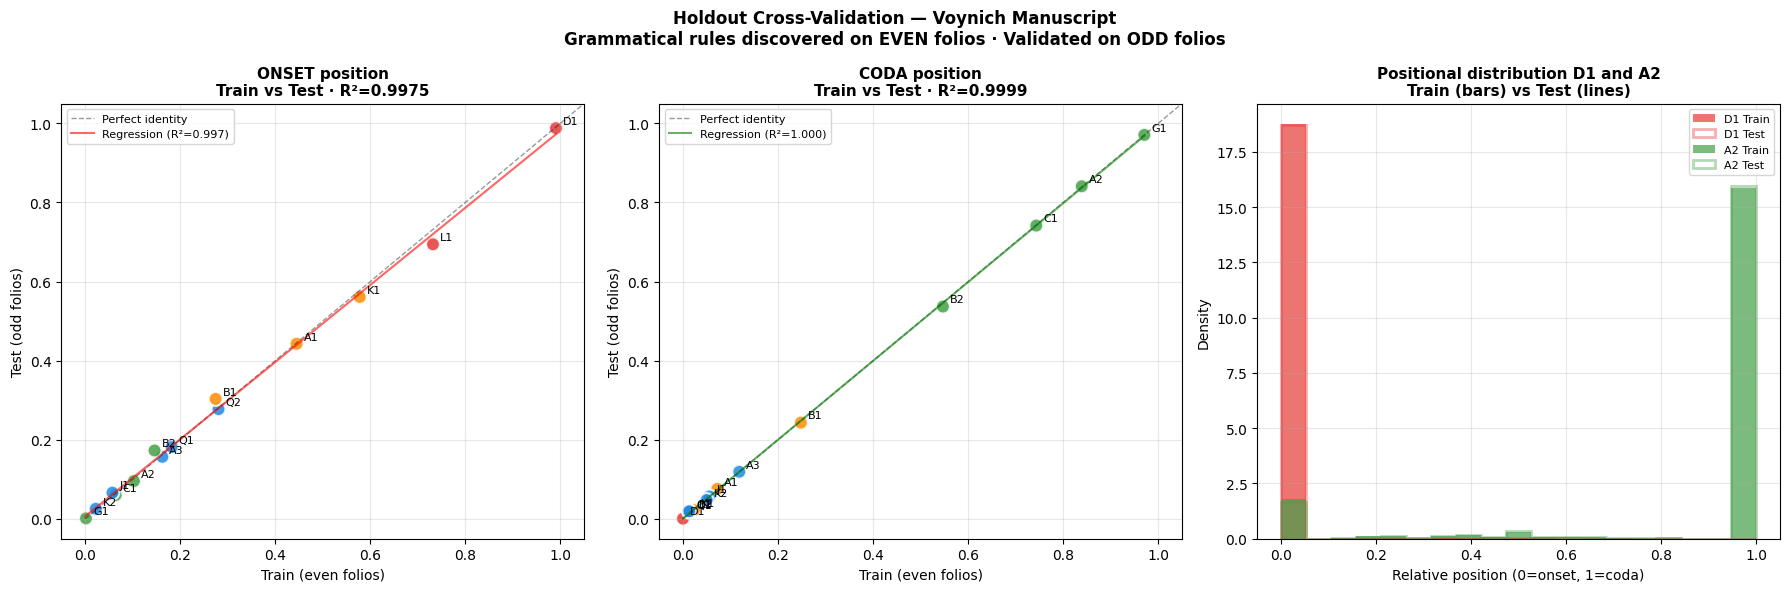

In [35]:
# ══════════════════════════════════════════════════════════════════
# BLOCK B — CROSS-VALIDATION WITH HOLDOUT
# ══════════════════════════════════════════════════════════════════
#
# Why is this necessary?
# The circularity problem: we used all folios to
# discover the grammatical rules AND to validate them.
# A reviewer would say: "aren't you seeing what you want to see?"
#
# The solution is holdout: split the corpus in two halves
# BEFORE doing any analysis. Discover the rules in one
# half (training set). Validate that the same rules appear
# in the other half (test set) — which the model never saw.
#
# If the rules are real, they should replicate in the half
# that was not used for discovering them.
# ══════════════════════════════════════════════════════════════════

import numpy as np
from scipy import stats
from collections import defaultdict
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import re

def crear_holdout_por_folio(filepath, mapeo_secciones, semilla=42):
    """
    Splits the corpus into training (even folios) and test (odd folios).
    The split is by complete folio — we never split words
    from the same folio between train and test.
    
    Why by folio and not by word?
    Because words from the same folio may be correlated
    (same scribe, same topic). Splitting by folio is more
    conservative and more convincing for a reviewer.
    """
    # First collect all folios and their words
    palabras_por_folio = defaultdict(list)
    folio_actual = None
    
    with open(filepath, 'r', encoding='utf-8') as f:
        for linea in f:
            linea = linea.strip()
            if not linea or linea.startswith('#'):
                continue
            
            m_folio = re.match(r'^<(f\d+[rv][ab]?\d*)>', linea)
            if m_folio:
                folio_actual = m_folio.group(1)
                continue
            
            if folio_actual is None:
                continue
                
            match = re.match(r'^<[^>]+>\s+(.*)', linea)
            if not match:
                continue
            
            texto = match.group(1).strip()
            texto = re.sub(r'\{[^}]*\}', '', texto)
            texto = re.sub(r'<[^>]*>', '', texto)
            texto = re.sub(r'-', '.', texto)
            
            for palabra_raw in texto.split('.'):
                palabra_raw = palabra_raw.strip()
                if not palabra_raw:
                    continue
                glifos = [g for g in re.findall(r'[A-Z][0-9a-z]?', palabra_raw)
                         if len(g) == 2]
                if glifos:
                    palabras_por_folio[folio_actual].append(glifos)
    
    # Split folios into train/test by even/odd number
    folios_todos = sorted(palabras_por_folio.keys(),
                          key=lambda x: int(re.search(r'\d+', x).group()))
    
    def num_folio(tag):
        return int(re.search(r'\d+', tag).group())
    
    folios_train = [f for f in folios_todos if num_folio(f) % 2 == 0]
    folios_test  = [f for f in folios_todos if num_folio(f) % 2 == 1]
    
    # Aggregate words by split and section
    train = defaultdict(list)
    test  = defaultdict(list)
    
    for folio in folios_train:
        sec = mapeo_secciones.get(folio, 'unknown')
        train[sec].extend(palabras_por_folio[folio])
        train['_all'].extend(palabras_por_folio[folio])
    
    for folio in folios_test:
        sec = mapeo_secciones.get(folio, 'unknown')
        test[sec].extend(palabras_por_folio[folio])
        test['_all'].extend(palabras_por_folio[folio])
    
    print("=== TRAIN/TEST SPLIT ===\n")
    print(f"  Train folios (even):  {len(folios_train)}")
    print(f"  Test folios (odd):    {len(folios_test)}")
    print(f"  Train folios (even):  {folios_train}")
    print(f"  Test folios (odd):    {folios_test}")
    
    print(f"\n  {'Split':<8} {'Words':>10} {'Glyphs':>10}")
    print("  " + "─" * 32)
    
    n_train = len(train['_all'])
    n_test  = len(test['_all'])
    g_train = sum(len(p) for p in train['_all'])
    g_test  = sum(len(p) for p in test['_all'])
    
    print(f"  {'Train':<8} {n_train:>10,} {g_train:>10,}")
    print(f"  {'Test':<8}  {n_test:>10,} {g_test:>10,}")
    print(f"  {'Ratio':<8} {n_train/n_test:>10.2f}x")
    
    return train, test, folios_train, folios_test


def calcular_perfil_posicional(palabras, morfemas):
    """
    Computes the positional profile of a list of morphemes
    over a set of words.
    Returns dict: morpheme → (onset%, medial%, coda%, n)
    """
    perfiles = {}
    
    for morfema in morfemas:
        posiciones = []
        for palabra in palabras:
            if morfema not in palabra:
                continue
            n = len(palabra)
            for i, g in enumerate(palabra):
                if g == morfema:
                    pos = 0.5 if n == 1 else i / (n - 1)
                    posiciones.append(pos)
        
        if not posiciones:
            perfiles[morfema] = None
            continue
        
        inicio = sum(1 for p in posiciones if p < 0.25) / len(posiciones)
        medio  = sum(1 for p in posiciones if 0.25 <= p <= 0.75) / len(posiciones)
        final  = sum(1 for p in posiciones if p > 0.75) / len(posiciones)
        perfiles[morfema] = (inicio, medio, final, len(posiciones))
    
    return perfiles


def validacion_cruzada_holdout(train, test, morfemas_clave):
    """
    Compares the positional profile of each morpheme between train and test.
    
    If the grammatical rules are real:
    - D1's profile in train should be ~equal to test
    - Differences should be small and not systematic
    
    Agreement metric: Pearson correlation between train and test
    profiles. R² close to 1 = rules replicate.
    """
    print("\n" + "=" * 75)
    print("BLOCK B — HOLDOUT CROSS-VALIDATION")
    print("Discovery on EVEN folios → Validation on ODD folios")
    print("=" * 75)
    
    perf_train = calcular_perfil_posicional(train['_all'], morfemas_clave)
    perf_test  = calcular_perfil_posicional(test['_all'],  morfemas_clave)
    
    print(f"\n{'Morpheme':<8} {'TRAIN onset':>13} {'TEST onset':>12} "
          f"{'Δ':>6} {'TRAIN coda':>12} {'TEST coda':>11} {'Δ':>6} {'Agreement'}")
    print("─" * 85)
    
    deltas_inicio = []
    deltas_final  = []
    train_inicios = []
    test_inicios  = []
    train_finales = []
    test_finales  = []
    
    for morfema in morfemas_clave:
        pt = perf_train.get(morfema)
        pv = perf_test.get(morfema)
        
        if pt is None or pv is None:
            print(f"{morfema:<8} {'N/A':>13}")
            continue
        
        delta_i = abs(pt[0] - pv[0])
        delta_f = abs(pt[2] - pv[2])
        deltas_inicio.append(delta_i)
        deltas_final.append(delta_f)
        
        train_inicios.append(pt[0])
        test_inicios.append(pv[0])
        train_finales.append(pt[2])
        test_finales.append(pv[2])
        
        # Qualitative agreement
        def categoria(inicio, final):
            if inicio > 0.6:  return 'PREFIX'
            if final > 0.6:   return 'SUFFIX'
            if inicio < 0.25 and final < 0.25: return 'ROOT'
            return 'FREE'
        
        cat_train = categoria(pt[0], pt[2])
        cat_test  = categoria(pv[0], pv[2])
        acuerdo = '✓' if cat_train == cat_test else '✗ DISAGREES'
        
        print(f"{morfema:<8} {pt[0]:>13.1%} {pv[0]:>12.1%} "
              f"{delta_i:>6.1%} {pt[2]:>12.1%} {pv[2]:>11.1%} "
              f"{delta_f:>6.1%} {acuerdo} ({cat_train})")
    
    # Global train vs test correlation
    r_inicio, p_inicio = stats.pearsonr(train_inicios, test_inicios)
    r_final,  p_final  = stats.pearsonr(train_finales, test_finales)
    
    print(f"\n=== TRAIN ↔ TEST CORRELATION ===")
    print(f"  Onset position:  r={r_inicio:.4f}, R²={r_inicio**2:.4f}, "
          f"p={p_inicio:.2e}")
    print(f"  Coda position:   r={r_final:.4f},  R²={r_final**2:.4f}, "
          f"p={p_final:.2e}")
    print(f"\n  Mean delta (onset): {np.mean(deltas_inicio):.2%}")
    print(f"  Mean delta (coda):  {np.mean(deltas_final):.2%}")
    
    if r_inicio > 0.95 and r_final > 0.95:
        print(f"\n  ✓✓ EXCELLENT REPLICATION — R²>{0.95**2:.2f}")
        print(f"     Grammatical rules replicate with high fidelity")
        print(f"     in the holdout set not seen during analysis.")
    elif r_inicio > 0.90:
        print(f"\n  ✓ GOOD REPLICATION — R²>{0.90**2:.2f}")
    else:
        print(f"\n  ⚠ MODERATE REPLICATION — review discrepant morphemes")
    
    return perf_train, perf_test, r_inicio, r_final


def visualizar_holdout(perf_train, perf_test, morfemas_clave,
                       r_inicio, r_final):
    """
    Three panels:
    1. Scatter train vs test for onset position
    2. Scatter train vs test for coda position
    3. Full comparative profile for D1 and A2
    """
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    
    morfemas_validos = [m for m in morfemas_clave
                        if perf_train.get(m) and perf_test.get(m)]
    
    inicios_tr = [perf_train[m][0] for m in morfemas_validos]
    inicios_te = [perf_test[m][0]  for m in morfemas_validos]
    finales_tr = [perf_train[m][2] for m in morfemas_validos]
    finales_te = [perf_test[m][2]  for m in morfemas_validos]
    
    PREFIJOS = {'D1','L1','Da'}
    SUFIJOS  = {'A2','C1','G1','B2'}
    RAICES   = {'Q1','Q2','A3','J1','K2'}
    
    def color_morfema(m):
        if m in PREFIJOS: return '#E53935'
        if m in SUFIJOS:  return '#43A047'
        if m in RAICES:   return '#1E88E5'
        return '#FB8C00'
    
    colores_m = [color_morfema(m) for m in morfemas_validos]
    
    # Panel 1: scatter onset position
    ax1 = axes[0]
    ax1.scatter(inicios_tr, inicios_te, c=colores_m,
                s=100, alpha=0.85, edgecolors='white', linewidths=1.5)
    
    for m, x, y in zip(morfemas_validos, inicios_tr, inicios_te):
        ax1.annotate(m, (x, y), fontsize=8,
                    xytext=(5, 3), textcoords='offset points')
    
    # Perfect identity line
    lim = [0, 1.05]
    ax1.plot(lim, lim, 'k--', alpha=0.4, linewidth=1, label='Perfect identity')
    
    # Regression line
    m_reg, b_reg = np.polyfit(inicios_tr, inicios_te, 1)
    xs = np.linspace(0, max(inicios_tr), 100)
    ax1.plot(xs, m_reg*xs + b_reg, 'r-', alpha=0.6, linewidth=1.5,
             label=f'Regression (R²={r_inicio**2:.3f})')
    
    ax1.set_xlabel("Train (even folios)")
    ax1.set_ylabel("Test (odd folios)")
    ax1.set_title(f"ONSET position\nTrain vs Test · R²={r_inicio**2:.4f}",
                 fontsize=11, fontweight='bold')
    ax1.legend(fontsize=8)
    ax1.grid(True, alpha=0.3)
    ax1.set_xlim(-0.05, 1.05)
    ax1.set_ylim(-0.05, 1.05)
    
    # Panel 2: scatter coda position
    ax2 = axes[1]
    ax2.scatter(finales_tr, finales_te, c=colores_m,
                s=100, alpha=0.85, edgecolors='white', linewidths=1.5)
    
    for m, x, y in zip(morfemas_validos, finales_tr, finales_te):
        ax2.annotate(m, (x, y), fontsize=8,
                    xytext=(5, 3), textcoords='offset points')
    
    ax2.plot(lim, lim, 'k--', alpha=0.4, linewidth=1, label='Perfect identity')
    
    m_reg2, b_reg2 = np.polyfit(finales_tr, finales_te, 1)
    xs2 = np.linspace(0, max(finales_tr), 100)
    ax2.plot(xs2, m_reg2*xs2 + b_reg2, 'g-', alpha=0.6, linewidth=1.5,
             label=f'Regression (R²={r_final**2:.3f})')
    
    ax2.set_xlabel("Train (even folios)")
    ax2.set_ylabel("Test (odd folios)")
    ax2.set_title(f"CODA position\nTrain vs Test · R²={r_final**2:.4f}",
                 fontsize=11, fontweight='bold')
    ax2.legend(fontsize=8)
    ax2.grid(True, alpha=0.3)
    ax2.set_xlim(-0.05, 1.05)
    ax2.set_ylim(-0.05, 1.05)
    
    # Panel 3: full profiles D1 and A2
    ax3 = axes[2]
    
    bins = np.linspace(0, 1, 20)
    
    for morfema, color, ls in [('D1', '#E53935', '-'), ('A2', '#43A047', '--')]:
        if perf_train.get(morfema) is None:
            continue
        
        # Recompute full distribution for histogram
        for split_name, palabras_split, alpha in [
            ('Train', train['_all'], 0.7),
            ('Test',  test['_all'],  0.4)
        ]:
            posiciones = []
            for palabra in palabras_split:
                n = len(palabra)
                for i, g in enumerate(palabra):
                    if g == morfema:
                        pos = 0.5 if n == 1 else i / (n - 1)
                        posiciones.append(pos)
            
            if posiciones:
                ax3.hist(posiciones, bins=bins, alpha=alpha,
                        color=color, density=True,
                        label=f'{morfema} {split_name}',
                        histtype='step' if split_name == 'Test' else 'bar',
                        linewidth=2 if split_name == 'Test' else 0)
    
    ax3.set_xlabel("Relative position (0=onset, 1=coda)")
    ax3.set_ylabel("Density")
    ax3.set_title("Positional distribution D1 and A2\nTrain (bars) vs Test (lines)",
                 fontsize=11, fontweight='bold')
    ax3.legend(fontsize=8)
    ax3.grid(True, alpha=0.3)
    
    plt.suptitle("Holdout Cross-Validation — Voynich Manuscript\n"
                 "Grammatical rules discovered on EVEN folios · "
                 "Validated on ODD folios",
                 fontsize=12, fontweight='bold')
    
    plt.tight_layout()
    plt.savefig('images/validacion_holdout.png', dpi=180,
                bbox_inches='tight', facecolor='white')
    plt.show()


# ── RUN BLOCK B ─────────────────────────────────────────────────

morfemas_clave = ['D1','L1','K1','A1','Q1','Q2',
                  'A2','A3','C1','B1','B2','G1','J1','K2']

FILEPATH = 'corpus/voynich_sta.txt'   # ← same as before

# Load with folio-level split
train, test, folios_train, folios_test = crear_holdout_por_folio(
    FILEPATH, mapeo_secciones)

# Cross-validation
perf_train, perf_test, r_inicio, r_final = validacion_cruzada_holdout(
    train, test, morfemas_clave)

# Visualization
visualizar_holdout(perf_train, perf_test, morfemas_clave,
                   r_inicio, r_final)

In [36]:
def unir_corpus(palabras_por_seccion):
    corpus = []
    for seccion in palabras_por_seccion.values():
        corpus.extend(seccion)
    return corpus

corpus_original = unir_corpus(palabras_por_seccion)
len(corpus_original)  # should be 37,087

37087

In [37]:
from collections import defaultdict

def fuerza_posicional(corpus):
    conteo = defaultdict(lambda: {"inicio":0, "medio":0, "final":0, "total":0})
    
    for palabra in corpus:
        n = len(palabra)
        for i, token in enumerate(palabra):
            conteo[token]["total"] += 1
            
            if i == 0:
                conteo[token]["inicio"] += 1
            elif i == n-1:
                conteo[token]["final"] += 1
            else:
                conteo[token]["medio"] += 1
    
    fuerza = {}
    for token, vals in conteo.items():
        total = vals["total"]
        inicio = vals["inicio"] / total
        final  = vals["final"]  / total
        
        fuerza[token] = max(inicio, final)
    
    return fuerza
fuerza_posicional(corpus_original)

{'P2': 0.2964705882352941,
 'A3': 0.13482296321760054,
 'K1': 0.532803180914513,
 'A2': 0.8378378378378378,
 'C2': 0.43990130419457174,
 'Q1': 0.10488173125314544,
 'B2': 0.5192163479565054,
 'C1': 0.7295420974889217,
 'Aa': 0.33550913838120106,
 'Q2': 0.15900539833142482,
 'G1': 0.9687650168188371,
 'L1': 0.6899856252994729,
 'A1': 0.33374492153270136,
 'U5': 0.6363636363636364,
 'J1': 0.006629618796919177,
 'B1': 0.28307281738467405,
 'U1': 0.19884393063583816,
 'F3': 0.7479935794542536,
 'E1': 0.03389830508474576,
 'U2': 0.5050279329608939,
 'E2': 0.8613138686131386,
 'G3': 0.8295454545454546,
 'K2': 0.005402971634398919,
 'S2': 0.7058823529411765,
 'T1': 0.5586854460093896,
 'T2': 0.5223880597014925,
 'Lp': 0.75,
 'F1': 0.9648917495611469,
 'Ab': 0.8324873096446701,
 'S1': 0.47368421052631576,
 'F2': 0.012345679012345678,
 'W2': 0.2857142857142857,
 'Ba': 0.15512159174649964,
 'B3': 0.9305164319248826,
 'P1': 0.3668515950069348,
 'Ci': 0.75,
 'Rd': 1.0,
 'H1': 0.9491525423728814,
 

In [38]:
import random
import numpy as np
from collections import defaultdict

# 1) Intra-word permutation
def permutar_intra_palabra(corpus, seed=None):
    rng = random.Random(seed)
    corpus_perm = []
    
    for palabra in corpus:
        if len(palabra) <= 1:
            corpus_perm.append(palabra.copy())
        else:
            nueva = palabra.copy()
            rng.shuffle(nueva)
            corpus_perm.append(nueva)
    
    return corpus_perm


# 2) Positional strength
def fuerza_posicional(corpus):
    conteo = defaultdict(lambda: {"onset":0, "medial":0, "coda":0, "total":0})
    
    for palabra in corpus:
        n = len(palabra)
        for i, token in enumerate(palabra):
            conteo[token]["total"] += 1
            
            if i == 0:
                conteo[token]["onset"] += 1
            elif i == n-1:
                conteo[token]["coda"] += 1
            else:
                conteo[token]["medial"] += 1
    
    fuerza = {}
    for token, vals in conteo.items():
        total = vals["total"]
        onset = vals["onset"] / total
        coda  = vals["coda"]  / total
        
        fuerza[token] = max(onset, coda)
    
    return fuerza


# 3) Permutation test
def test_token(corpus, token, n_perm=2000):
    fuerza_obs = fuerza_posicional(corpus)[token]
    
    dist_perm = []
    
    for i in range(n_perm):
        corpus_perm = permutar_intra_palabra(corpus, seed=i)
        fuerza_perm = fuerza_posicional(corpus_perm)[token]
        dist_perm.append(fuerza_perm)
    
    dist_perm = np.array(dist_perm)
    
    p_value = np.mean(dist_perm >= fuerza_obs)
    
    return {
        "observed": fuerza_obs,
        "perm_mean": dist_perm.mean(),
        "perm_std": dist_perm.std(),
        "p_value": p_value
    }

print(test_token(corpus_original, "D1"))
print(test_token(corpus_original, "G1"))
print(test_token(corpus_original, "A2"))

{'observed': 0.9865437788018433, 'perm_mean': np.float64(0.1983036866359447), 'perm_std': np.float64(0.004270035216192093), 'p_value': np.float64(0.0)}
{'observed': 0.9687650168188371, 'perm_mean': np.float64(0.28461052378664103), 'perm_std': np.float64(0.0049539013988482705), 'p_value': np.float64(0.0)}
{'observed': 0.8378378378378378, 'perm_mean': np.float64(0.236033211177279), 'perm_std': np.float64(0.0029505557793233165), 'p_value': np.float64(0.0)}


In [39]:
import numpy as np
import pandas as pd
from tqdm.notebook import tqdm

def test_todos_tokens(corpus, n_perm=1000):
    
    fuerza_obs_dict = fuerza_posicional(corpus)
    tokens = list(fuerza_obs_dict.keys())
    
    # Pre-compute all permutations once (instead of per-token)
    all_perm_fuerzas = []
    for i in tqdm(range(n_perm), desc="Permuting corpus"):
        corpus_perm = permutar_intra_palabra(corpus, seed=i)
        all_perm_fuerzas.append(fuerza_posicional(corpus_perm))
    
    resultados = []
    
    for token in tokens:
        
        fuerza_obs = fuerza_obs_dict[token]
        dist_perm = np.array([pf[token] for pf in all_perm_fuerzas])
        p_valor = np.mean(dist_perm >= fuerza_obs)
        
        resultados.append({
            "token": token,
            "fuerza_obs": fuerza_obs,
            "media_perm": dist_perm.mean(),
            "std_perm": dist_perm.std(),
            "p_valor": p_valor
        })
    
    df = pd.DataFrame(resultados)
    df = df.sort_values("fuerza_obs", ascending=False).reset_index(drop=True)
    
    n_sig = (df["p_valor"] < 0.001).sum()
    
    print(f"\nTotal tokens: {len(df)}")
    print(f"Tokens con p < 0.001: {n_sig}")
    
    return df

df_resultados = test_todos_tokens(corpus_original, n_perm=1000)
df_resultados.head(15)

Permuting corpus:   0%|          | 0/1000 [00:00<?, ?it/s]


Total tokens: 166
Tokens con p < 0.001: 32


,token,fuerza_obs,media_perm,std_perm,p_valor
0,Rd,1.0,0.492,0.499936,0.492
1,Xl,1.0,1.000,0.000000,1.000
2,Yd,1.0,0.494,0.499964,0.494
3,Ys,1.0,0.490,0.499900,0.490
4,Sf,1.0,0.384,0.486358,0.384
5,Wb,1.0,1.000,0.000000,1.000
6,Wm,1.0,1.000,0.000000,1.000
7,Th,1.0,1.000,0.000000,1.000
8,Wq,1.0,1.000,0.000000,1.000
9,Tg,1.0,1.000,0.000000,1.000


In [40]:
from collections import Counter

def frecuencia_tokens(corpus):
    c = Counter()
    for palabra in corpus:
        for token in palabra:
            c[token] += 1
    return c

freq_dict = frecuencia_tokens(corpus_original)
df_resultados["frecuencia"] = df_resultados["token"].map(freq_dict)

df_filtrado = df_resultados[df_resultados["frecuencia"] >= 20].copy()

print("Tokens totales:", len(df_resultados))
print("Tokens con freq >= 20:", len(df_filtrado))
print("Significativos (p<0.001):", (df_filtrado["p_valor"] < 0.001).sum())

df_filtrado.head(15)

Tokens totales: 166
Tokens con freq >= 20: 44
Significativos (p<0.001): 26


,token,fuerza_obs,media_perm,std_perm,p_valor,frecuencia
47,D1,0.986544,0.198372,0.004211,0.0,5425
48,G1,0.968765,0.284588,0.005057,0.0,4162
49,F1,0.964892,0.258578,0.007836,0.0,1709
50,H1,0.949153,0.367588,0.024895,0.0,177
51,B3,0.930516,0.263131,0.009648,0.0,1065
53,B4,0.866667,0.275848,0.028572,0.0,165
54,E2,0.861314,0.275015,0.027124,0.0,137
56,A2,0.837838,0.235973,0.002886,0.0,17464
59,Ab,0.832487,0.239272,0.015683,0.0,394
60,G3,0.829545,0.323313,0.023643,0.0,176


In [41]:
import numpy as np
from collections import defaultdict

def construir_tabla_tp(corpus):
    conteo_tp = defaultdict(int)
    conteo_t = defaultdict(int)
    conteo_p = defaultdict(int)
    
    total = 0
    
    for palabra in corpus:
        n = len(palabra)
        for i, token in enumerate(palabra):
            
            if i == 0:
                pos = "inicio"
            elif i == n-1:
                pos = "final"
            else:
                pos = "medio"
            
            conteo_tp[(token, pos)] += 1
            conteo_t[token] += 1
            conteo_p[pos] += 1
            total += 1
    
    return conteo_tp, conteo_t, conteo_p, total

In [42]:
import math

def mutual_information(corpus):
    conteo_tp, conteo_t, conteo_p, total = construir_tabla_tp(corpus)
    
    mi = 0.0
    
    for (token, pos), count_tp in conteo_tp.items():
        p_tp = count_tp / total
        p_t  = conteo_t[token] / total
        p_p  = conteo_p[pos] / total
        
        mi += p_tp * math.log(p_tp / (p_t * p_p), 2)  # log base 2 (bits)
    
    return mi

In [43]:
mi_obs = mutual_information(corpus_original)
print("Observed mutual information:", mi_obs)

Mutual Inshapetion observada: 0.6578108986209191


In [44]:
from tqdm.notebook import tqdm

def test_mi_global(corpus, n_perm=500):
    mi_obs = mutual_information(corpus)
    
    dist_perm = []
    
    for i in tqdm(range(n_perm), desc="Permutando MI"):
        corpus_perm = permutar_intra_palabra(corpus, seed=i)
        mi_perm = mutual_information(corpus_perm)
        dist_perm.append(mi_perm)
    
    dist_perm = np.array(dist_perm)
    
    p_valor = np.mean(dist_perm >= mi_obs)
    
    return {
        "mi_obs": mi_obs,
        "media_perm": dist_perm.mean(),
        "std_perm": dist_perm.std(),
        "p_valor": p_valor
    }

resultado_mi = test_mi_global(corpus_original, n_perm=500)
resultado_mi

Permutando MI:   0%|          | 0/500 [00:00<?, ?it/s]

{'mi_obs': 0.6578108986209191,
 'media_perm': np.float64(0.007992870061230142),
 'std_perm': np.float64(0.00031781784885969073),
 'p_valor': np.float64(0.0)}

In [45]:
from tqdm.notebook import tqdm
import numpy as np
import pandas as pd

def mi_por_seccion(palabras_por_seccion, n_perm=300):
    
    resultados = []
    
    for nombre, corpus in palabras_por_seccion.items():
        
        print(f"\nSection: {nombre}")
        
        # Observed MI
        mi_obs = mutual_information(corpus)
        
        # Permutations
        dist_perm = []
        for i in tqdm(range(n_perm), desc=f"Permuting {nombre}"):
            corpus_perm = permutar_intra_palabra(corpus, seed=i)
            mi_perm = mutual_information(corpus_perm)
            dist_perm.append(mi_perm)
        
        dist_perm = np.array(dist_perm)
        p_value = np.mean(dist_perm >= mi_obs)
        
        resultados.append({
            "section": nombre,
            "n_words": len(corpus),
            "mi_obs": mi_obs,
            "perm_mean": dist_perm.mean(),
            "perm_std": dist_perm.std(),
            "p_value": p_value
        })
    
    df = pd.DataFrame(resultados)
    return df

df_mi_secciones = mi_por_seccion(palabras_por_seccion, n_perm=300)
df_mi_secciones


Section: herbal


Permuting herbal:   0%|          | 0/300 [00:00<?, ?it/s]


Section: astronomical


Permuting astronomical:   0%|          | 0/300 [00:00<?, ?it/s]


Section: zodiac


Permuting zodiac:   0%|          | 0/300 [00:00<?, ?it/s]

... (3 outputs left out)

Permuting pharmaceutical:   0%|          | 0/300 [00:00<?, ?it/s]


Section: recipes


Permuting recipes:   0%|          | 0/300 [00:00<?, ?it/s]

,section,n_words,mi_obs,perm_mean,perm_std,p_value
0,herbal,14278,0.606841,0.010884,0.000529,0.0
1,astronomical,1342,0.577332,0.021240,0.002303,0.0
2,zodiac,1588,0.636047,0.015527,0.001710,0.0
3,biological,6768,0.804507,0.009090,0.000769,0.0
4,pharmaceutical,2505,0.669693,0.016407,0.001441,0.0
5,recipes,10606,0.729393,0.009896,0.000688,0.0


In [46]:
import requests

url = "https://www.gutenberg.org/files/1342/1342-0.txt"
texto = requests.get(url).text

In [47]:
import re

def procesar_texto(texto):
    palabras = re.findall(r"[a-zA-Z]+", texto.lower())
    return [[c for c in palabra] for palabra in palabras if len(palabra) > 1]

corpus_natural = procesar_texto(texto)

In [48]:
mi_natural = mutual_information(corpus_natural)
print("Natural language MI:", mi_natural)

MI natural: 0.23195052318409298


In [49]:
resultado_natural_perm = test_mi_global(corpus_natural, n_perm=200)
resultado_natural_perm

Permutando MI:   0%|          | 0/200 [00:00<?, ?it/s]

{'mi_obs': 0.23195052318409298,
 'media_perm': np.float64(0.012689488645226822),
 'std_perm': np.float64(0.00022523605832597922),
 'p_valor': np.float64(0.0)}

In [50]:
import random

def generar_corpus_slot(
    n_palabras=37000,
    n_prefijos=3,
    n_raices=20,
    n_sufijos=3,
    seed=42
):
    random.seed(seed)
    
    prefijos = [f"P{i}" for i in range(n_prefijos)]
    raices = [f"R{i}" for i in range(n_raices)]
    sufijos = [f"S{i}" for i in range(n_sufijos)]
    
    corpus = []
    
    for _ in range(n_palabras):
        palabra = [
            random.choice(prefijos),
            random.choice(raices),
            random.choice(sufijos)
        ]
        corpus.append(palabra)
    
    return corpus

corpus_slot = generar_corpus_slot()

In [51]:
mi_slot = mutual_information(corpus_slot)
print("Artificial slot MI:", mi_slot)

MI slot artificial: 1.584962500721156


In [52]:
resultado_slot_perm = test_mi_global(corpus_slot, n_perm=200)
resultado_slot_perm

Permutando MI:   0%|          | 0/200 [00:00<?, ?it/s]

{'mi_obs': 1.584962500721156,
 'media_perm': np.float64(0.0003335564907237734),
 'std_perm': np.float64(6.573465014328773e-05),
 'p_valor': np.float64(0.0)}

In [53]:
import random

def generar_corpus_slot_prob(
    n_palabras=37000,
    n_prefijos=5,
    n_raices=30,
    n_sufijos=5,
    p_pref=0.85,
    p_root=0.85,
    p_suf=0.85,
    seed=42
):
    random.seed(seed)
    
    prefijos = [f"P{i}" for i in range(n_prefijos)]
    raices = [f"R{i}" for i in range(n_raices)]
    sufijos = [f"S{i}" for i in range(n_sufijos)]
    
    vocab_total = prefijos + raices + sufijos
    
    corpus = []
    
    for _ in range(n_palabras):
        palabra = []
        
        # Onset
        if random.random() < p_pref:
            palabra.append(random.choice(prefijos))
        else:
            palabra.append(random.choice(vocab_total))
        
        # Medial
        if random.random() < p_root:
            palabra.append(random.choice(raices))
        else:
            palabra.append(random.choice(vocab_total))
        
        # Coda
        if random.random() < p_suf:
            palabra.append(random.choice(sufijos))
        else:
            palabra.append(random.choice(vocab_total))
        
        corpus.append(palabra)
    
    return corpus

In [54]:
corpus_slot_prob = generar_corpus_slot_prob(p_pref=0.85, p_root=0.85, p_suf=0.85)

mi_slot_prob = mutual_information(corpus_slot_prob)
print("Probabilistic slot MI (p=0.85):", mi_slot_prob)

MI probabilistic slot (p=0.85): 1.061131532406253


In [55]:
for p in [0.95, 0.85, 0.75, 0.65, 0.55]:
    corpus_test = generar_corpus_slot_prob(p_pref=p, p_root=p, p_suf=p)
    mi_test = mutual_information(corpus_test)
    print(f"p={p} -> MI={mi_test:.3f}")

p=0.95 -> MI=1.358
p=0.85 -> MI=1.061
p=0.75 -> MI=0.821
p=0.65 -> MI=0.635
p=0.55 -> MI=0.468


In [56]:
import math
from collections import Counter

def mutual_information_bigram(corpus):
    """
    Compute MI(Token_i ; Token_i+1)
    """
    bigram_counts = Counter()
    unigram_counts = Counter()
    
    total_bigrams = 0
    total_tokens = 0
    
    for palabra in corpus:
        total_tokens += len(palabra)
        unigram_counts.update(palabra)
        
        for i in range(len(palabra) - 1):
            bigram = (palabra[i], palabra[i+1])
            bigram_counts[bigram] += 1
            total_bigrams += 1
    
    mi = 0.0
    
    for (t1, t2), count in bigram_counts.items():
        p_xy = count / total_bigrams
        p_x = unigram_counts[t1] / total_tokens
        p_y = unigram_counts[t2] / total_tokens
        
        mi += p_xy * math.log2(p_xy / (p_x * p_y))
    
    return mi

In [57]:
mi_bigram_obs = mutual_information_bigram(corpus_original)
print("Observed bigram MI:", mi_bigram_obs)

MI bigram observada: 1.6811319175050217


In [58]:
for p in [0.95, 0.85, 0.75, 0.65]:
    corpus_test = generar_corpus_slot_prob(p_pref=p, p_root=p, p_suf=p)
    mi_test = mutual_information_bigram(corpus_test)
    print(f"Slot p={p} -> MI_bigram={mi_test:.4f}")

Slot p=0.95 -> MI_bigram=1.7953
Slot p=0.85 -> MI_bigram=1.3052
Slot p=0.75 -> MI_bigram=0.9413
Slot p=0.65 -> MI_bigram=0.6855


In [59]:
def bigram_mi_contributions(corpus, top_n=30):
    import math
    from collections import Counter
    
    bigram_counts = Counter()
    unigram_counts = Counter()
    
    total_bigrams = 0
    total_tokens = 0
    
    for palabra in corpus:
        total_tokens += len(palabra)
        unigram_counts.update(palabra)
        
        for i in range(len(palabra) - 1):
            bigram_counts[(palabra[i], palabra[i+1])] += 1
            total_bigrams += 1
    
    results = []
    
    for (t1, t2), count in bigram_counts.items():
        p_xy = count / total_bigrams
        p_x = unigram_counts[t1] / total_tokens
        p_y = unigram_counts[t2] / total_tokens
        
        contrib = p_xy * math.log2(p_xy / (p_x * p_y))
        
        results.append((t1, t2, count, contrib))
    
    # sort by contribution descending
    results.sort(key=lambda x: x[3], reverse=True)
    
    return results[:top_n]

In [60]:
top_pairs = bigram_mi_contributions(corpus_original, top_n=30)

for t1, t2, count, contrib in top_pairs:
    print(f"{t1} -> {t2} | freq={count} | contrib_MI={contrib:.4f}")

D1 -> A1 | freq=5292 | contrib_MI=0.1321
A3 -> G1 | freq=3905 | contrib_MI=0.1212
A1 -> Q1 | freq=6037 | contrib_MI=0.1164
K1 -> J1 | freq=4311 | contrib_MI=0.1064
B1 -> A2 | freq=5015 | contrib_MI=0.1041
A1 -> B2 | freq=5570 | contrib_MI=0.0972
A1 -> Q2 | freq=4005 | contrib_MI=0.0808
A3 -> C1 | freq=3411 | contrib_MI=0.0804
B1 -> A3 | freq=3468 | contrib_MI=0.0642
A3 -> B2 | freq=3187 | contrib_MI=0.0552
Q1 -> K2 | freq=2014 | contrib_MI=0.0542
A3 -> F1 | freq=1673 | contrib_MI=0.0528
Q1 -> A3 | freq=2973 | contrib_MI=0.0515
L1 -> J1 | freq=1910 | contrib_MI=0.0508
J1 -> B1 | freq=2530 | contrib_MI=0.0479
Ba -> A2 | freq=1775 | contrib_MI=0.0435
A1 -> C1 | freq=2567 | contrib_MI=0.0349
K2 -> A2 | freq=1696 | contrib_MI=0.0306
J1 -> Ba | freq=1114 | contrib_MI=0.0282
Q1 -> J1 | freq=1791 | contrib_MI=0.0276
Q2 -> A3 | freq=1600 | contrib_MI=0.0251
J1 -> A1 | freq=2627 | contrib_MI=0.0234
J1 -> A2 | freq=2103 | contrib_MI=0.0223
A3 -> B3 | freq=779 | contrib_MI=0.0219
P1 -> K1 | freq=7

In [61]:
import numpy as np
from collections import Counter

def build_transition_matrix(corpus):
    bigram_counts = Counter()
    unigram_counts = Counter()
    
    for palabra in corpus:
        unigram_counts.update(palabra)
        for i in range(len(palabra) - 1):
            bigram_counts[(palabra[i], palabra[i+1])] += 1
    
    tokens = sorted(unigram_counts.keys())
    index = {tok: i for i, tok in enumerate(tokens)}
    
    n = len(tokens)
    M = np.zeros((n, n))
    
    for (t1, t2), count in bigram_counts.items():
        i = index[t1]
        j = index[t2]
        M[i, j] = count
    
    # normalizar por fila → probabilityes conditionales
    for i in range(n):
        row_sum = M[i].sum()
        if row_sum > 0:
            M[i] /= row_sum
    
    return M, tokens

In [62]:
M, tokens = build_transition_matrix(corpus_original)

eigvals = np.linalg.eigvals(M)

# sort by magnitude
eigvals_sorted = sorted(np.abs(eigvals), reverse=True)

print("Top 10 eigenvalues:")
for val in eigvals_sorted[:10]:
    print(val)

Top 10 eigenvalores:
0.9997392977098094
0.5768172883806844
0.5071360206199625
0.465131018229558
0.465131018229558
0.41596513231323723
0.24234019187816774
0.2127390558165372
0.2127390558165372
0.12858606257658714


=== TRAIN / TEST SPLIT ===

  Train folios (even):  116
  Test folios (odd):    110

  Split         Words     Glyphs
  ────────────────────────────────
  Train        18,916     80,873
  Test          18,171     76,381
  Ratio          1.04x

BLOCK B — HOLDOUT CROSS-VALIDATION
Rules discovered on EVEN folios → Validated on ODD folios

Morpheme  TRAIN ini  TEST ini   Δini  TRAIN fin  TEST fin   Δfin  Agreement
────────────────────────────────────────────────────────────────────────────────
D1            99.1%     98.8%   0.3%       0.0%      0.1%   0.1%  ✓ (PREFIX)
L1            73.2%     69.4%   3.8%       1.9%      2.1%   0.2%  ✓ (PREFIX)
K1            57.8%     56.1%   1.7%       2.3%      2.2%   0.1%  ✓ (FREE)
A1            44.5%     44.3%   0.2%       7.2%      7.6%   0.4%  ✓ (FREE)
Q1            18.2%     18.2%   0.1%       1.3%      1.8%   0.5%  ✓ (ROOT)
Q2            28.1%     27.7%   0.3%       1.3%      2.0%   0.6%  ✓ (FREE)
A2            10.3%      9.6%   0.7%      83.9%    

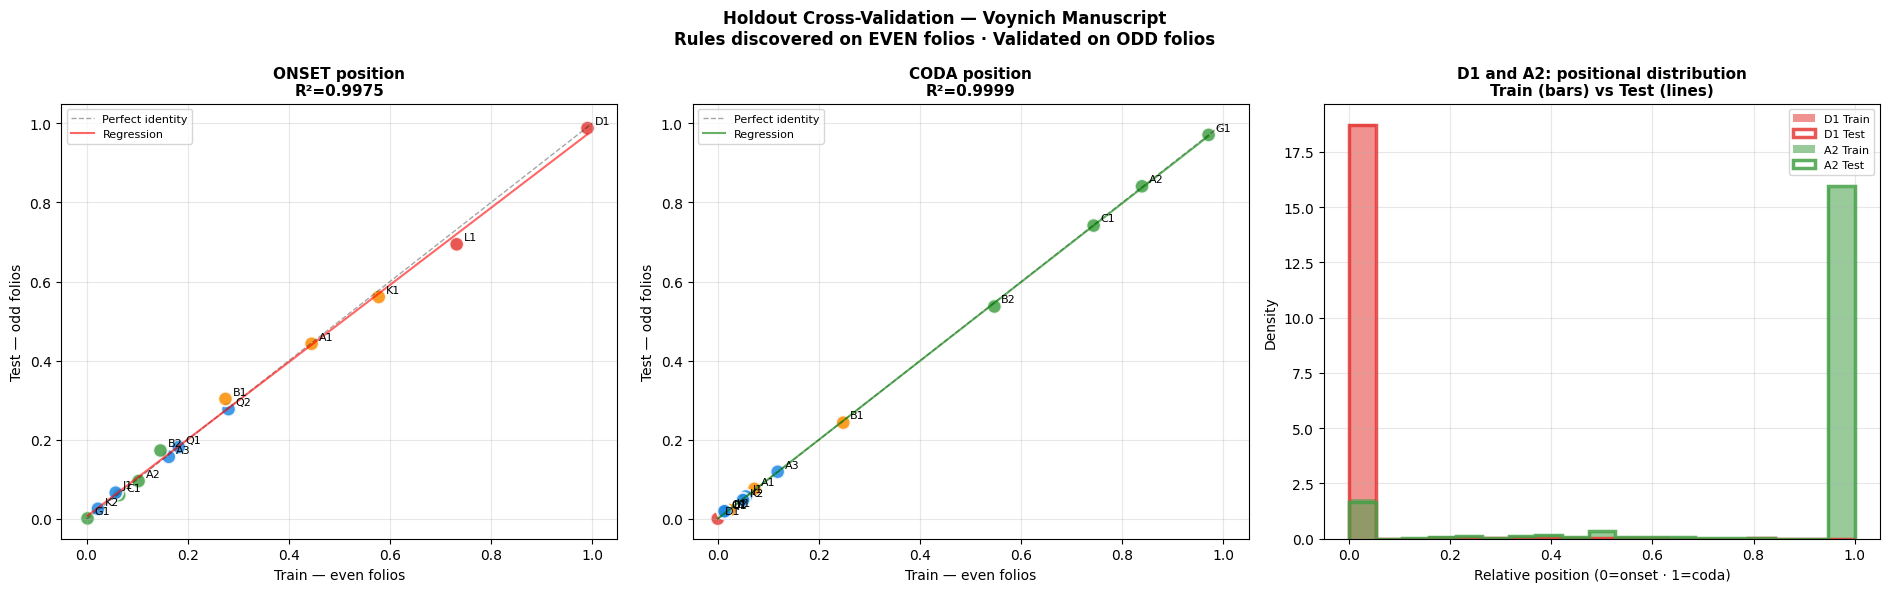

In [63]:
# ══════════════════════════════════════════════════════════════════
# BLOCK B — CROSS-VALIDATION WITH HOLDOUT
# ══════════════════════════════════════════════════════════════════
import numpy as np
from scipy import stats
from collections import defaultdict
import matplotlib.pyplot as plt
import re

def crear_holdout_por_folio(filepath, mapeo_secciones):
    """
    Splits the corpus into train (even folios) and test (odd folios).
    Split by complete folio — we never split words from the same
    folio between the two sets.
    """
    palabras_por_folio = defaultdict(list)
    folio_actual = None
    
    with open(filepath, 'r', encoding='utf-8') as f:
        for linea in f:
            linea = linea.strip()
            if not linea or linea.startswith('#'):
                continue
            m_folio = re.match(r'^<(f\d+[rv][ab]?\d*)>', linea)
            if m_folio:
                folio_actual = m_folio.group(1)
                continue
            if folio_actual is None:
                continue
            match = re.match(r'^<[^>]+>\s+(.*)', linea)
            if not match:
                continue
            texto = match.group(1).strip()
            texto = re.sub(r'\{[^}]*\}', '', texto)
            texto = re.sub(r'<[^>]*>', '', texto)
            texto = re.sub(r'-', '.', texto)
            for palabra_raw in texto.split('.'):
                palabra_raw = palabra_raw.strip()
                if not palabra_raw:
                    continue
                glifos = [g for g in re.findall(r'[A-Z][0-9a-z]?', palabra_raw)
                         if len(g) == 2]
                if glifos:
                    palabras_por_folio[folio_actual].append(glifos)
    
    # Split by even/odd folio number
    folios_todos = sorted(palabras_por_folio.keys(),
                          key=lambda x: int(re.search(r'\d+', x).group()))
    
    def num_folio(tag):
        return int(re.search(r'\d+', tag).group())
    
    folios_train = [f for f in folios_todos if num_folio(f) % 2 == 0]
    folios_test  = [f for f in folios_todos if num_folio(f) % 2 == 1]
    
    train = defaultdict(list)
    test  = defaultdict(list)
    
    for folio in folios_train:
        sec = mapeo_secciones.get(folio, 'unknown')
        train[sec].extend(palabras_por_folio[folio])
        train['_all'].extend(palabras_por_folio[folio])
    
    for folio in folios_test:
        sec = mapeo_secciones.get(folio, 'unknown')
        test[sec].extend(palabras_por_folio[folio])
        test['_all'].extend(palabras_por_folio[folio])
    
    print("=== TRAIN / TEST SPLIT ===\n")
    print(f"  Train folios (even):  {len(folios_train)}")
    print(f"  Test folios (odd):    {len(folios_test)}")
    n_train = len(train['_all'])
    n_test  = len(test['_all'])
    g_train = sum(len(p) for p in train['_all'])
    g_test  = sum(len(p) for p in test['_all'])
    print(f"\n  {'Split':<8} {'Words':>10} {'Glyphs':>10}")
    print("  " + "─" * 32)
    print(f"  {'Train':<8} {n_train:>10,} {g_train:>10,}")
    print(f"  {'Test':<8}  {n_test:>10,} {g_test:>10,}")
    print(f"  {'Ratio':<8} {n_train/n_test:>10.2f}x")
    
    return train, test, folios_train, folios_test


def calcular_perfil_posicional(palabras, morfemas):
    perfiles = {}
    for morfema in morfemas:
        posiciones = []
        for palabra in palabras:
            if morfema not in palabra:
                continue
            n = len(palabra)
            for i, g in enumerate(palabra):
                if g == morfema:
                    pos = 0.5 if n == 1 else i / (n - 1)
                    posiciones.append(pos)
        if not posiciones:
            perfiles[morfema] = None
            continue
        inicio = sum(1 for p in posiciones if p < 0.25) / len(posiciones)
        medio  = sum(1 for p in posiciones if 0.25 <= p <= 0.75) / len(posiciones)
        final  = sum(1 for p in posiciones if p > 0.75) / len(posiciones)
        perfiles[morfema] = (inicio, medio, final, len(posiciones))
    return perfiles


def validacion_cruzada_holdout(train, test, morfemas_clave):
    print("\n" + "=" * 80)
    print("BLOCK B — HOLDOUT CROSS-VALIDATION")
    print("Rules discovered on EVEN folios → Validated on ODD folios")
    print("=" * 80)
    
    perf_train = calcular_perfil_posicional(train['_all'], morfemas_clave)
    perf_test  = calcular_perfil_posicional(test['_all'],  morfemas_clave)
    
    print(f"\n{'Morpheme':<8} {'TRAIN ini':>10} {'TEST ini':>9} {'Δini':>6} "
          f"{'TRAIN fin':>10} {'TEST fin':>9} {'Δfin':>6}  Agreement")
    print("─" * 80)
    
    deltas_inicio, deltas_final   = [], []
    train_inicios, test_inicios   = [], []
    train_finales, test_finales   = [], []
    morfemas_validos              = []
    
    for morfema in morfemas_clave:
        pt = perf_train.get(morfema)
        pv = perf_test.get(morfema)
        if pt is None or pv is None:
            print(f"{morfema:<8}  N/A")
            continue
        
        delta_i = abs(pt[0] - pv[0])
        delta_f = abs(pt[2] - pv[2])
        deltas_inicio.append(delta_i)
        deltas_final.append(delta_f)
        train_inicios.append(pt[0])
        test_inicios.append(pv[0])
        train_finales.append(pt[2])
        test_finales.append(pv[2])
        morfemas_validos.append(morfema)
        
        def categoria(ini, fin):
            if ini > 0.60: return 'PREFIX'
            if fin > 0.60: return 'SUFFIX'
            if ini < 0.25 and fin < 0.25: return 'ROOT'
            return 'FREE'
        
        cat_tr = categoria(pt[0], pt[2])
        cat_te = categoria(pv[0], pv[2])
        acuerdo = '✓' if cat_tr == cat_te else '✗ DISAGREES'
        
        print(f"{morfema:<8} {pt[0]:>10.1%} {pv[0]:>9.1%} {delta_i:>6.1%} "
              f"{pt[2]:>10.1%} {pv[2]:>9.1%} {delta_f:>6.1%}  "
              f"{acuerdo} ({cat_tr})")
    
    r_ini, p_ini = stats.pearsonr(train_inicios, test_inicios)
    r_fin, p_fin = stats.pearsonr(train_finales, test_finales)
    
    print(f"\n=== TRAIN ↔ TEST CORRELATION ===")
    print(f"  Onset position:  r={r_ini:.4f}  R²={r_ini**2:.4f}  p={p_ini:.2e}")
    print(f"  Coda position:   r={r_fin:.4f}  R²={r_fin**2:.4f}  p={p_fin:.2e}")
    print(f"\n  Mean delta onset: {np.mean(deltas_inicio):.2%}")
    print(f"  Mean delta coda:  {np.mean(deltas_final):.2%}")
    
    if r_ini**2 > 0.95 and r_fin**2 > 0.95:
        print(f"\n  ✓✓ EXCELLENT REPLICATION")
        print(f"     Grammatical rules replicate with high fidelity")
        print(f"     in the holdout set not seen during analysis.")
    elif r_ini**2 > 0.90:
        print(f"\n  ✓ GOOD REPLICATION")
    else:
        print(f"\n  ⚠ MODERATE REPLICATION")
    
    return perf_train, perf_test, r_ini, r_fin, morfemas_validos


def visualizar_holdout(perf_train, perf_test, morfemas_validos,
                       train, test, r_ini, r_fin):
    
    fig, axes = plt.subplots(1, 3, figsize=(19, 6))
    
    inicios_tr = [perf_train[m][0] for m in morfemas_validos]
    inicios_te = [perf_test[m][0]  for m in morfemas_validos]
    finales_tr = [perf_train[m][2] for m in morfemas_validos]
    finales_te = [perf_test[m][2]  for m in morfemas_validos]
    
    PREFIJOS = {'D1','L1','Da'}
    SUFIJOS  = {'A2','C1','G1','B2'}
    RAICES   = {'Q1','Q2','A3','J1','K2'}
    
    def color_m(m):
        if m in PREFIJOS: return '#E53935'
        if m in SUFIJOS:  return '#43A047'
        if m in RAICES:   return '#1E88E5'
        return '#FB8C00'
    
    colores_m = [color_m(m) for m in morfemas_validos]
    
    for ax, tr_vals, te_vals, r, titulo, color_reg in [
        (axes[0], inicios_tr, inicios_te, r_ini,
         f"ONSET position\nR²={r_ini**2:.4f}", 'red'),
        (axes[1], finales_tr, finales_te, r_fin,
         f"CODA position\nR²={r_fin**2:.4f}", 'green'),
    ]:
        ax.scatter(tr_vals, te_vals, c=colores_m,
                   s=110, alpha=0.85, edgecolors='white', linewidths=1.5)
        for m, x, y in zip(morfemas_validos, tr_vals, te_vals):
            ax.annotate(m, (x, y), fontsize=8,
                       xytext=(5, 3), textcoords='offset points')
        ax.plot([0,1], [0,1], 'k--', alpha=0.35, linewidth=1,
                label='Perfect identity')
        if len(tr_vals) > 1:
            mb, bb = np.polyfit(tr_vals, te_vals, 1)
            xs = np.linspace(min(tr_vals), max(tr_vals), 100)
            ax.plot(xs, mb*xs + bb, color=color_reg, alpha=0.6,
                   linewidth=1.5, label=f'Regression')
        ax.set_xlabel("Train — even folios", fontsize=10)
        ax.set_ylabel("Test — odd folios", fontsize=10)
        ax.set_title(titulo, fontsize=11, fontweight='bold')
        ax.legend(fontsize=8)
        ax.grid(True, alpha=0.3)
        ax.set_xlim(-0.05, 1.05)
        ax.set_ylim(-0.05, 1.05)
    
    # Panel 3: positional distribution D1 and A2 train vs test
    ax3 = axes[2]
    bins = np.linspace(0, 1, 20)
    
    for morfema, color in [('D1', '#E53935'), ('A2', '#43A047')]:
        for split_name, palabras_split, alpha, htype in [
            ('Train', train['_all'], 0.55, 'bar'),
            ('Test',  test['_all'],  0.85, 'step'),
        ]:
            posiciones = []
            for palabra in palabras_split:
                n = len(palabra)
                for i, g in enumerate(palabra):
                    if g == morfema:
                        pos = 0.5 if n == 1 else i / (n - 1)
                        posiciones.append(pos)
            if posiciones:
                ax3.hist(posiciones, bins=bins, alpha=alpha,
                        color=color, density=True,
                        label=f'{morfema} {split_name}',
                        histtype=htype,
                        linewidth=2.5 if htype == 'step' else 0)
    
    ax3.set_xlabel("Relative position (0=onset · 1=coda)")
    ax3.set_ylabel("Density")
    ax3.set_title("D1 and A2: positional distribution\nTrain (bars) vs Test (lines)",
                 fontsize=11, fontweight='bold')
    ax3.legend(fontsize=8)
    ax3.grid(True, alpha=0.3)
    
    plt.suptitle("Holdout Cross-Validation — Voynich Manuscript\n"
                 "Rules discovered on EVEN folios · Validated on ODD folios",
                 fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.savefig('images/validacion_holdout.png', dpi=180,
                bbox_inches='tight', facecolor='white')
    plt.show()


# ── RUN BLOCK B ─────────────────────────────────────────────────

morfemas_clave = ['D1','L1','K1','A1','Q1','Q2',
                  'A2','A3','C1','B1','B2','G1','J1','K2']

train, test, folios_train, folios_test = crear_holdout_por_folio(
    FILEPATH, mapeo_secciones)

perf_train, perf_test, r_ini, r_fin, morfemas_validos = \
    validacion_cruzada_holdout(train, test, morfemas_clave)

visualizar_holdout(perf_train, perf_test, morfemas_validos,
                   train, test, r_ini, r_fin)